
# Preparación y análisis del dataset Cassava

**Asignatura:** Inteligencia Artificial  
**Proyecto:** Clasificación de enfermedades foliares de yuca  
**Grupo:** 1

## Objetivo
Analizar las características, etiquetas, distribución e imágenes del dataset Cassava y preparar los datos para el entrenamiento de cuatro arquitecturas CNN: CNN propia, MobileNetV2, EfficientNetB0 y DenseNet121.

In [8]:
# PASO 1: Importación y verificación de librerías
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path
from datetime import datetime
from time import perf_counter
import csv

# Mostrar versiones utilizadas
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
# Comprobar si existe una GPU disponible
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponible: []

Librerías importadas correctamente.


In [9]:
# PASO 2: Carga del dataset Cassava
# Descargar el dataset y cargar sus tres particiones originales
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    with_info=True,
    as_supervised=False,
    shuffle_files=False
)
# Confirmar que el dataset fue cargado correctamente
print("Cassava descargado y particiones cargadas correctamente.")

Cassava descargado y particiones cargadas correctamente.


In [10]:
# PASO 3: Análisis de metadatos del dataset Cassava
# Mostrar información general del dataset
print("Nombre del dataset:", info.name)
print("Versión:", info.version)

# Mostrar la cantidad de imágenes por conjunto
print("\n--- DISTRIBUCIÓN DE DATOS ---")
total = 0

for nombre, datos in info.splits.items():
    print(f"{nombre}: {datos.num_examples} imágenes")
    total += datos.num_examples

print("Total de imágenes:", total)

# Mostrar la cantidad de clases y sus etiquetas
print("\n--- CLASES Y ETIQUETAS ---")
clases = info.features["label"].names

print("Número de clases:", len(clases))

for codigo, nombre in enumerate(clases):
    print(f"Etiqueta {codigo}: {nombre}")

# Mostrar las características de las imágenes
print("\n--- CARACTERÍSTICAS DE LAS IMÁGENES ---")
print("Dimensiones:", info.features["image"].shape)
print("Tipo de dato:", info.features["image"].np_dtype)
print("Características disponibles:", list(info.features.keys()))

Nombre del dataset: cassava
Versión: 0.1.0

--- DISTRIBUCIÓN DE DATOS ---
train: 5656 imágenes
test: 1885 imágenes
validation: 1889 imágenes
Total de imágenes: 9430

--- CLASES Y ETIQUETAS ---
Número de clases: 5
Etiqueta 0: cbb
Etiqueta 1: cbsd
Etiqueta 2: cgm
Etiqueta 3: cmd
Etiqueta 4: healthy

--- CARACTERÍSTICAS DE LAS IMÁGENES ---
Dimensiones: (None, None, 3)
Tipo de dato: <class 'numpy.uint8'>
Características disponibles: ['image', 'image/filename', 'label']


In [11]:
# PASO 3.1: Análisis de clases y dimensiones de las imágenes
from collections import Counter
# Contadores de etiquetas y dimensiones
conteo_clases = Counter()
conteo_tamanos = Counter()

# Recorrer las imágenes originales de los tres conjuntos
for dataset in (ds_train, ds_val, ds_test):
    for registro in tfds.as_numpy(dataset):
        conteo_clases[int(registro["label"])] += 1

        alto, ancho = registro["image"].shape[:2]
        conteo_tamanos[(ancho, alto)] += 1

# Mostrar cantidad de imágenes por clase
print("--- IMÁGENES POR CLASE ---")
for i, clase in enumerate(clases):
    print(f"Etiqueta {i} ({clase}): {conteo_clases[i]} imágenes")

print("Total:", sum(conteo_clases.values()))

# Identificar las dimensiones mínima, máxima y más frecuente
menor = min(conteo_tamanos, key=lambda x: x[0] * x[1])
mayor = max(conteo_tamanos, key=lambda x: x[0] * x[1])
frecuente, cantidad = conteo_tamanos.most_common(1)[0]

# Mostrar resultados de las dimensiones
print("\n--- DIMENSIONES DE LAS IMÁGENES ---")
print("Tamaño más pequeño:", menor)
print("Tamaño más grande:", mayor)
print("Tamaño más frecuente:", frecuente)
print("Imágenes con ese tamaño mas frecuentes:", cantidad)
print("Tamaños diferentes encontrados:", len(conteo_tamanos))

--- IMÁGENES POR CLASE ---
Etiqueta 0 (cbb): 777 imágenes
Etiqueta 1 (cbsd): 2406 imágenes
Etiqueta 2 (cgm): 1289 imágenes
Etiqueta 3 (cmd): 4431 imágenes
Etiqueta 4 (healthy): 527 imágenes
Total: 9430

--- DIMENSIONES DE LAS IMÁGENES ---
Tamaño más pequeño: (420, 500)
Tamaño más grande: (1622, 500)
Tamaño más frecuente: (500, 666)
Imágenes con ese tamaño mas frecuentes: 2369
Tamaños diferentes encontrados: 669


In [12]:
# PASO 3.2: Distribución de clases en Train, Validation y Test
# Crear los conjuntos que vamos a analizar
particiones = {
    "Train": ds_train,
    "Validation": ds_val,
    "Test": ds_test
}

# Contar las etiquetas de cada conjunto
conteos = {}

for nombre, dataset in particiones.items():
    etiquetas = [
        int(x) for x in tfds.as_numpy(
            dataset.map(lambda registro: registro["label"])
        )
    ]
    conteos[nombre] = np.bincount(etiquetas, minlength=len(clases))

# Mostrar una tabla comparativa
print(f"{'Clase':<10} {'Train':>8} {'Validation':>12} {'Test':>8}")

for i, clase in enumerate(clases):
    print(f"{clase:<10} {conteos['Train'][i]:>8} "
          f"{conteos['Validation'][i]:>12} {conteos['Test'][i]:>8}")

# Comprobar los totales de cada partición
print("\nTotales:")
for nombre, cantidades in conteos.items():
    print(f"{nombre}: {cantidades.sum()} imágenes")

Clase         Train   Validation     Test
cbb             466          156      155
cbsd           1443          482      481
cgm             773          258      258
cmd            2658          887      886
healthy         316          106      105

Totales:
Train: 5656 imágenes
Validation: 1889 imágenes
Test: 1885 imágenes


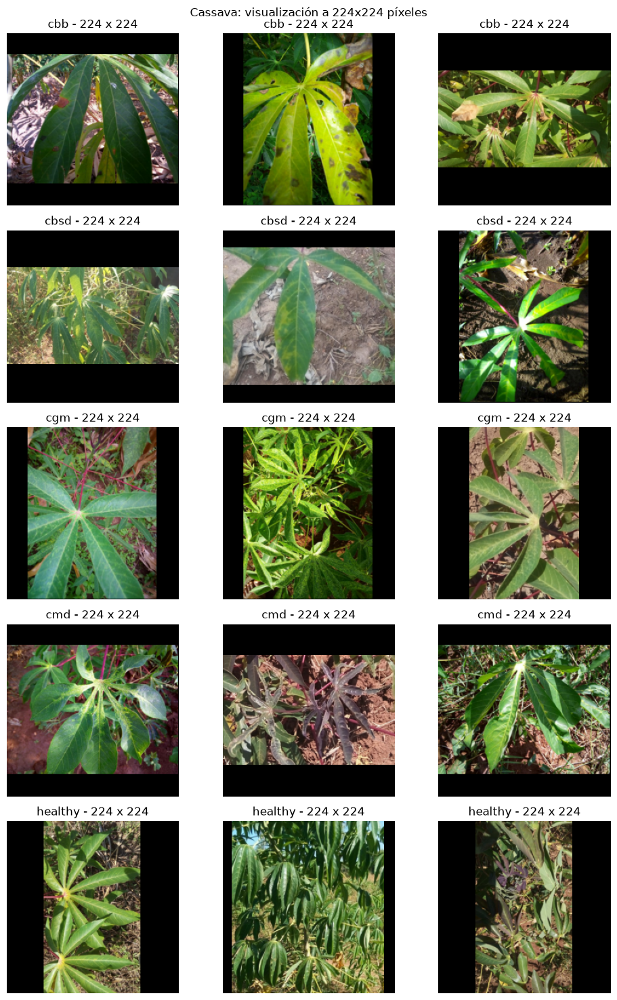

In [13]:
# PASO 4: Visualización de imágenes redimensionadas a 224x224
# Seleccionar 3 imágenes de cada clase del conjunto Train
muestras = {i: [] for i in range(len(clases))}

for registro in tfds.as_numpy(ds_train):
    etiqueta = int(registro["label"])

    if len(muestras[etiqueta]) < 3:
        muestras[etiqueta].append(registro["image"])

    # Detener cuando tengamos las 15 imágenes
    if all(len(lista) == 3 for lista in muestras.values()):
        break

# Mostrar las 15 imágenes con resolución de 224x224
fig, ejes = plt.subplots(5, 3, figsize=(10, 15))

for i, clase in enumerate(clases):
    for j, imagen in enumerate(muestras[i]):
        # Redimensionar conservando la proporción original
        imagen_224 = tf.image.resize_with_pad(
            imagen, 224, 224, antialias=True
        )
        # Visualizar la imagen con su etiqueta
        ejes[i, j].imshow(tf.cast(imagen_224, tf.uint8))
        ejes[i, j].set_title(f"{clase} - 224 x 224")
        ejes[i, j].axis("off")

plt.suptitle("Cassava: visualización a 224x224 píxeles")
plt.tight_layout()
plt.show()

In [14]:
# PASO 5: Preparación de datos para el entrenamiento
# Definir parámetros generales
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Función para redimensionar cada imagen y conservar su etiqueta
def preparar_imagen(registro):
    imagen = tf.image.resize_with_pad(
        registro["image"],
        IMG_SIZE[0],
        IMG_SIZE[1],
        antialias=True,)
    # Mantener los píxeles float32 en el rango común de 0 a 255.
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]
# Función para organizar los datos en lotes
def preparar_dataset(dataset, entrenamiento=False):

    # Mezclar únicamente las imágenes de entrenamiento
    if entrenamiento:
        dataset = dataset.shuffle(1000, seed=42)
    # Redimensionar las imágenes
    dataset = dataset.map(
        preparar_imagen, num_parallel_calls=AUTOTUNE
    )
    # Agrupar las imágenes y optimizar su lectura
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset
# Preparar Train, Validation y Test
train_preparado = preparar_dataset(ds_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val)
test_preparado = preparar_dataset(ds_test)

print("Datos preparados correctamente.")

# Comprobar las dimensiones de un lote
for imagenes, etiquetas in train_preparado.take(1):
    print("Dimensiones del lote:", imagenes.shape)
    print("Dimensiones de etiquetas:", etiquetas.shape)
    print("Tipo de dato:", imagenes.dtype)

Datos preparados correctamente.
Dimensiones del lote: (32, 224, 224, 3)
Dimensiones de etiquetas: (32,)
Tipo de dato: <dtype: 'float32'>


Clase        Fotos    Mediana        P90    Más de 50%
cbb            466      20.0%      24.9%          0.2%
cbsd          1443      24.9%      43.7%          0.0%
cgm            773      24.9%      43.7%          0.8%
cmd           2658      24.9%      43.7%          0.5%
healthy        316      20.0%      43.7%          0.6%


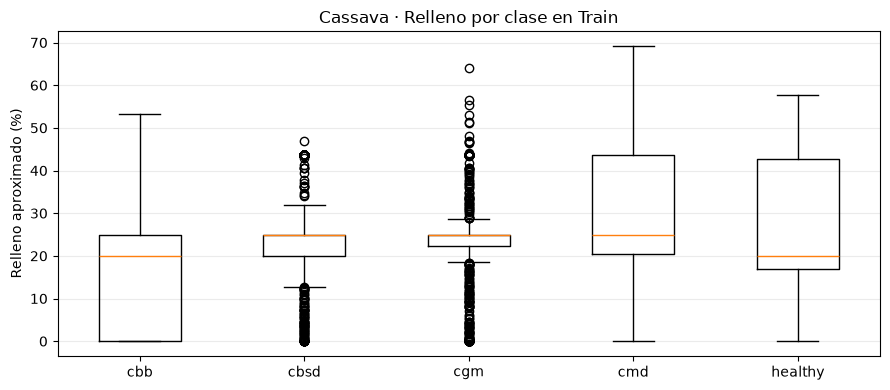

In [16]:
# PASO 6: Medir cuánto relleno necesita cada clase de Cassava
from collections import defaultdict

relleno_por_clase = defaultdict(list)

# Buscamos fotos casi cuadradas, moderadamente rectangulares y alargadas.
# El valor representa lado corto / lado largo.
proporciones_objetivo = [1.00, 0.75, 0.40]
muestras_comparacion = {}

for registro in tfds.as_numpy(ds_train):
    imagen = registro["image"]
    etiqueta = int(registro["label"])
    alto, ancho = imagen.shape[:2]

    proporcion = min(alto, ancho) / max(alto, ancho)
    porcentaje_relleno = 100 * (1 - proporcion)
    relleno_por_clase[etiqueta].append(porcentaje_relleno)

    # Guardar, para cada clase, la foto más cercana a cada proporción.
    for objetivo in proporciones_objetivo:
        clave = (etiqueta, objetivo)
        distancia = abs(proporcion - objetivo)
        anterior = muestras_comparacion.get(clave)

        if anterior is None or distancia < anterior["distancia"]:
            muestras_comparacion[clave] = {
                "distancia": distancia,
                "imagen": imagen,
                "relleno": porcentaje_relleno,
            }

print(f"{'Clase':<10} {'Fotos':>7} {'Mediana':>10} {'P90':>10} {'Más de 50%':>13}")

for etiqueta, nombre in enumerate(clases):
    valores = np.array(relleno_por_clase[etiqueta])

    print(
        f"{nombre:<10} {len(valores):>7} "
        f"{np.median(valores):>9.1f}% "
        f"{np.percentile(valores, 90):>9.1f}% "
        f"{np.mean(valores > 50) * 100:>12.1f}%"
    )

plt.figure(figsize=(9, 4))
plt.boxplot([relleno_por_clase[i] for i in range(len(clases))])
plt.xticks(range(1, len(clases) + 1), clases)
plt.ylabel("Relleno aproximado (%)")
plt.title("Cassava · Relleno por clase en Train")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

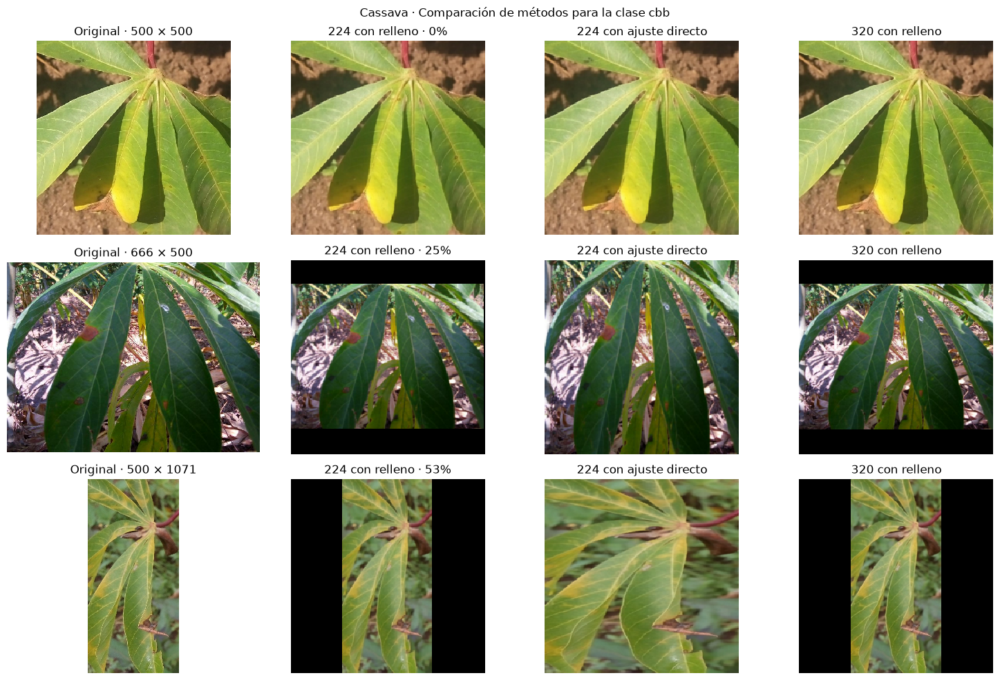

In [9]:
# PASO 7: Comparar el redimensionamiento sobre las mismas fotos
clase_a_revisar = "cbb"
etiqueta = list(clases).index(clase_a_revisar)

fig, ejes = plt.subplots(3, 4, figsize=(15, 10))

for fila, objetivo in enumerate(proporciones_objetivo):
    muestra = muestras_comparacion[(etiqueta, objetivo)]
    original = muestra["imagen"]
    alto, ancho = original.shape[:2]

    con_relleno_224 = tf.image.resize_with_pad(
        original, 224, 224, antialias=True
    )
    directo_224 = tf.image.resize(
        original, (224, 224), antialias=True
    )
    con_relleno_320 = tf.image.resize_with_pad(
        original, 320, 320, antialias=True
    )

    versiones = [
        (original, f"Original · {ancho} × {alto}"),
        (con_relleno_224, f"224 con relleno · {muestra['relleno']:.0f}%"),
        (directo_224, "224 con ajuste directo"),
        (con_relleno_320, "320 con relleno"),
    ]

    for eje, (imagen, titulo) in zip(ejes[fila], versiones):
        # Conversión solo para que Matplotlib muestre bien los colores.
        imagen_visible = np.clip(np.asarray(imagen), 0, 255).astype(np.uint8)
        eje.imshow(imagen_visible, interpolation="nearest")
        eje.set_title(titulo)
        eje.axis("off")

fig.suptitle(f"Cassava · Comparación de métodos para la clase {clase_a_revisar}")
plt.tight_layout()
plt.show()

In [10]:
print(f"Máximo real del lote: {tf.reduce_max(imagenes).numpy():.8f}")

Máximo real del lote: 255.00000000


In [11]:
# PASO 8: Verificar las entradas antes de entrenar la CNN propia
for nombre, dataset in [
    ("Train", train_preparado),
    ("Validation", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))

    tf.debugging.assert_shapes([
        (imagenes, ("lote", 224, 224, 3)),
        (etiquetas, ("lote",)),
    ])
    tf.debugging.assert_all_finite(imagenes, f"{nombre}: píxeles no finitos")
    tf.debugging.assert_greater_equal(imagenes, 0.0)
    tf.debugging.assert_less_equal(imagenes, 255.0)
    tf.debugging.assert_greater_equal(etiquetas, tf.cast(0, etiquetas.dtype))
    tf.debugging.assert_less(
        etiquetas, tf.cast(len(clases), etiquetas.dtype)
    )

    print(
        f"{nombre} | imágenes: {imagenes.shape} | "
        f"etiquetas: {etiquetas.shape} | "
        f"píxeles: {float(tf.reduce_min(imagenes)):.1f} a "
        f"{float(tf.reduce_max(imagenes)):.1f}"
    )
print("Los lotes de Train y Validation pasaron la verificación.")

Train | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Validation | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Los lotes de Train y Validation pasaron la verificación.


In [18]:
# PASO 9: Definir la arquitectura de la CNN propia ajustada.
# Cada bloque produce características nuevas y las une con las anteriores.

def convolucion_inicial(x, filtros, tamano_kernel, paso=1):
    x = layers.Conv2D(
        filtros,
        tamano_kernel,
        strides=paso,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
    )(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    return layers.ReLU()(x)


def bloque_ligero_denso(x, caracteristicas_nuevas):
    # Inspiración MobileNet: expandir, procesar por canal y comprimir.
    canales_expandidos = 2 * int(x.shape[-1])
    nuevas = convolucion_inicial(x, canales_expandidos, 1)

    nuevas = layers.DepthwiseConv2D(
        3,
        padding="same",
        use_bias=False,
        depthwise_initializer="he_normal",
    )(nuevas)
    nuevas = layers.BatchNormalization(momentum=0.9)(nuevas)
    nuevas = layers.ReLU()(nuevas)

    # Inspiración EfficientNet: aprender cuánto reforzar cada canal.
    atencion = layers.GlobalAveragePooling2D(keepdims=True)(nuevas)
    atencion = layers.Conv2D(
        max(canales_expandidos // 4, 8),
        1,
        activation="relu",
    )(atencion)
    atencion = layers.Conv2D(
        canales_expandidos,
        1,
        activation="sigmoid",
    )(atencion)
    nuevas = layers.Multiply()([nuevas, atencion])

    # Proyección lineal hacia un grupo pequeño de características nuevas.
    nuevas = layers.Conv2D(
        caracteristicas_nuevas,
        1,
        use_bias=False,
        kernel_initializer="he_normal",
    )(nuevas)
    nuevas = layers.BatchNormalization(momentum=0.9)(nuevas)

    # Inspiración DenseNet: conservar las características anteriores
    # y concatenarlas con las nuevas, dentro de cada grupo.
    return layers.Concatenate()([x, nuevas])


def construir_cnn_ajustada(tamano_imagen, numero_clases):
    entrada = keras.Input(
        shape=(*tamano_imagen, 3),
        name="imagen_rgb",
    )

    # Los datasets preparados entregan píxeles entre 0 y 255.
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(entrada)

    # Aprender características iniciales y reducir gradualmente la imagen.
    x = convolucion_inicial(x, 32, 3, paso=2)
    x = convolucion_inicial(x, 32, 3, paso=2)

    # Tres grupos con tres bloques cada uno.
    # Después de cada grupo se comprime la cantidad de canales.
    configuracion_grupos = [
        (16, 48),
        (24, 80),
        (32, 128),
    ]

    for indice, (crecimiento, canales_salida) in enumerate(configuracion_grupos):
        for _ in range(3):
            x = bloque_ligero_denso(x, crecimiento)

        x = convolucion_inicial(x, canales_salida, 1)

        # Reducir el tamaño espacial entre los grupos.
        if indice < len(configuracion_grupos) - 1:
            x = layers.AveragePooling2D(2)(x)

    x = layers.GlobalAveragePooling2D(name="resumen_global")(x)
    x = layers.Dropout(0.30, name="regularizacion")(x)

    salida = layers.Dense(
        numero_clases,
        activation="softmax",
        name="clasificacion",
    )(x)

    return keras.Model(
        entrada,
        salida,
        name="cnn_propia_ajustada",
    )


print("Arquitectura definida. El modelo se construirá al iniciar la corrida.")

Arquitectura definida. El modelo se construirá al iniciar la corrida.


In [13]:
# PASO 10: Primera corrida de la nueva CNN propia ajustada.
# Configuración inicial propuesta para comprobar la arquitectura.
SEMILLA = 42
EPOCAS_MAXIMAS = 30
TASA_APRENDIZAJE = 0.0003

# Calcular los pesos únicamente con los conteos de Train.
# La raíz cuadrada modera la compensación por desbalance.
conteos_train_ajustada = np.asarray(conteos["Train"], dtype=np.float64)

if (
    len(conteos_train_ajustada) != len(clases)
    or np.any(conteos_train_ajustada <= 0)
):
    raise ValueError("Revisa los conteos de Train y el orden de las clases.")

pesos_ajustada = 1.0 / np.sqrt(conteos_train_ajustada)
pesos_ajustada /= np.average(
    pesos_ajustada,
    weights=conteos_train_ajustada,
)
pesos_clase_ajustada = {
    indice: float(peso)
    for indice, peso in enumerate(pesos_ajustada)
}

# Construir un modelo con pesos nuevos para esta corrida.
keras.backend.clear_session()
keras.utils.set_random_seed(SEMILLA)

modelo_ajustado = construir_cnn_ajustada(IMG_SIZE, len(clases))
modelo_ajustado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=TASA_APRENDIZAJE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Reconstruir Train con el mismo procedimiento del Paso 5.
train_ajustada = preparar_dataset(ds_train, entrenamiento=True)

# Ubicar la carpeta del proyecto desde la raíz o desde cassava.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual
    if carpeta_actual.name.lower() == "cassava"
    else carpeta_actual / "cassava"
)

if not (carpeta_cassava / "CNN_Propia_ajustada.ipynb").is_file():
    raise FileNotFoundError(
        "Ejecuta desde la carpeta BeanCass AI o desde su carpeta cassava."
    )

nombre_corrida = datetime.now().strftime("ensayo_01_%Y%m%d_%H%M%S_%f")
carpeta_corrida_ajustada = (
    carpeta_cassava
    / "resultados"
    / "cnn_propia_ajustada"
    / nombre_corrida
)
carpeta_corrida_ajustada.mkdir(parents=True, exist_ok=False)
ruta_modelo_ajustado = carpeta_corrida_ajustada / "mejor_modelo.keras"

# Mostrar la configuración que se utilizará.
modelo_ajustado.summary()

print("\nPesos calculados con Train:")
for indice, nombre in enumerate(clases):
    print(
        f"{nombre}: {int(conteos_train_ajustada[indice])} fotos"
        f" · peso {pesos_clase_ajustada[indice]:.2f}"
    )

print(f"\nTasa de aprendizaje inicial: {TASA_APRENDIZAJE}")
print(f"Máximo de épocas: {EPOCAS_MAXIMAS}")
print("Carpeta de resultados:", carpeta_corrida_ajustada.resolve())

# Guardar el historial y el modelo con menor pérdida en Validation.
callbacks_ajustada = [
    keras.callbacks.CSVLogger(
        str(carpeta_corrida_ajustada / "historial.csv")
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_modelo_ajustado),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    ),
    # Reducir el tamaño de los ajustes cuando la validación se estanque.
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1,
    ),
    # Permitir varias épocas para observar el efecto de reducir la tasa.
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=6,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.TerminateOnNaN(),
]

inicio_ajustada = perf_counter()

historial_ajustada = modelo_ajustado.fit(
    train_ajustada,
    validation_data=val_preparado,
    class_weight=pesos_clase_ajustada,
    epochs=EPOCAS_MAXIMAS,
    callbacks=callbacks_ajustada,
    verbose=1,
)

# Mostrar los resultados de la época seleccionada por val_loss.
duracion_ajustada = perf_counter() - inicio_ajustada
indice_mejor_ajustada = int(
    np.argmin(historial_ajustada.history["val_loss"])
)
epoca_guardada_ajustada = indice_mejor_ajustada + 1

print(f"\nÉpocas ejecutadas: {len(historial_ajustada.history['loss'])}")
print(f"Época guardada: {epoca_guardada_ajustada}")
print(
    "Exactitud en validación: "
    f"{historial_ajustada.history['val_accuracy'][indice_mejor_ajustada]:.2%}"
)
print(
    "Pérdida en validación: "
    f"{historial_ajustada.history['val_loss'][indice_mejor_ajustada]:.4f}"
)
print(f"Tiempo de entrenamiento: {duracion_ajustada / 60:.2f} minutos")
print("Archivos guardados en:", carpeta_corrida_ajustada.resolve())

Model: "cnn_propia_ajustada"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imagen_rgb          │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalizacion       │ (None, 224, 224,  │          0 │ imagen_rgb[0][0]  │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        864 │ normalizacion[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │      2,048 │ re_lu_1[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 56, 56,    │        576 │ re_lu_2[0][0]     │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 1, 64)  │          0 │ re_lu_3[0][0]     │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 1, 1, 16)  │      1,040 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 1, 1, 64)  │      1,088 │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 365,953 (1.40 MB)

 Trainable params: 359,313 (1.37 MB)

 Non-trainable params: 6,640 (25.94 KB)


Pesos calculados con Train:
cbb: 466 fotos · peso 1.67
cbsd: 1443 fotos · peso 0.95
cgm: 773 fotos · peso 1.30
cmd: 2658 fotos · peso 0.70
healthy: 316 fotos · peso 2.03

Tasa de aprendizaje inicial: 0.0003
Máximo de épocas: 30
Carpeta de resultados: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_01_20261120_001728_038642
Epoch 1/30


c:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


177/177 ━━━━━━━━━━━━━━━━━━━━ 178s 852ms/step - accuracy: 0.5046 - loss: 1.3895 - val_accuracy: 0.5929 - val_loss: 1.1181 - learning_rate: 3.0000e-04
Epoch 2/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 141s 794ms/step - accuracy: 0.5994 - loss: 1.2177 - val_accuracy: 0.5469 - val_loss: 1.2136 - learning_rate: 3.0000e-04
Epoch 3/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 144s 809ms/step - accuracy: 0.6208 - loss: 1.1277 - val_accuracy: 0.6654 - val_loss: 0.9322 - learning_rate: 3.0000e-04
Epoch 4/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 148s 830ms/step - accuracy: 0.6466 - loss: 1.0595 - val_accuracy: 0.6411 - val_loss: 0.9602 - learning_rate: 3.0000e-04
Epoch 5/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 147s 828ms/step - accuracy: 0.6627 - loss: 1.0046 - val_accuracy: 0.6331 - val_loss: 0.9501 - learning_rate: 3.0000e-04
Epoch 6/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 752ms/step - accuracy: 0.6803 - loss: 0.9454
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
177/177 ━━━━━━━━━━━━━━━━━━━━ 143s 805ms/step - 

Épocas ejecutadas: 15
Época guardada y evaluada: 9
Imágenes de validación: 1889
Exactitud en validación: 71.78%
F1 macro: 0.6136

Clase    Aciertos    Precisión   Recall       F1
cbb        80/156      61.07%    51.28%   0.5575
cbsd      341/482      73.33%    70.75%   0.7202
cgm       110/258      55.56%    42.64%   0.4825
cmd       774/887      78.18%    87.26%   0.8247
healthy    51/106      48.57%    48.11%   0.4834

cgm → cmd: 98
healthy → cmd: 15
Hojas enfermas predichas como sanas: 54


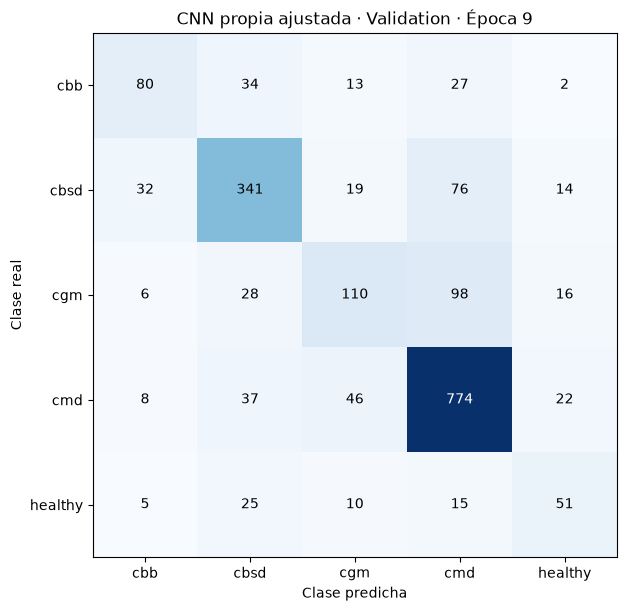


Matriz y reporte guardados en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_01_20261120_001728_038642


In [15]:
# PASO 11: Evaluar el modelo guardado de la CNN propia ajustada.
actual = Path.cwd()
cassava = actual if actual.name.lower() == "cassava" else actual / "cassava"

carpeta_evaluacion = (
    cassava
    / "resultados"
    / "cnn_propia_ajustada"
    / "ensayo_01_20261120_001728_038642"
)

# Leer el historial para identificar la época seleccionada por val_loss.
with (carpeta_evaluacion / "historial.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    registros_ajustada = list(csv.DictReader(archivo))

mejor_registro = min(
    registros_ajustada,
    key=lambda registro: float(registro["val_loss"]),
)
epoca_evaluada = int(mejor_registro["epoch"]) + 1

# Cargar el modelo guardado y evaluar las imágenes de Validation.
modelo_evaluado = keras.models.load_model(
    carpeta_evaluacion / "mejor_modelo.keras",
    compile=False,
)
nombres_clases = list(clases)
matriz_ajustada = np.zeros(
    (len(nombres_clases), len(nombres_clases)),
    dtype=int,
)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_evaluado(imagenes, training=False).numpy()
    predicciones = np.argmax(probabilidades, axis=1)
    reales_lote = etiquetas.numpy().astype(int)
    np.add.at(matriz_ajustada, (reales_lote, predicciones), 1)

# Comprobar que se evaluó la partición completa.
total_validacion = int(matriz_ajustada.sum())
esperadas = info.splits["validation"].num_examples

if total_validacion != esperadas:
    raise ValueError(
        f"Se evaluaron {total_validacion} imágenes; se esperaban {esperadas}."
    )

# Calcular las métricas de las cinco clases.
aciertos_ajustada = matriz_ajustada.diagonal()
reales_ajustada = matriz_ajustada.sum(axis=1)
predichas_ajustada = matriz_ajustada.sum(axis=0)

precision_ajustada = aciertos_ajustada / np.maximum(predichas_ajustada, 1)
recall_ajustada = aciertos_ajustada / np.maximum(reales_ajustada, 1)
f1_ajustada = (
    2 * aciertos_ajustada
    / np.maximum(reales_ajustada + predichas_ajustada, 1)
)
exactitud_ajustada = aciertos_ajustada.sum() / total_validacion

print(f"Épocas ejecutadas: {len(registros_ajustada)}")
print(f"Época guardada y evaluada: {epoca_evaluada}")
print(f"Imágenes de validación: {total_validacion}")
print(f"Exactitud en validación: {exactitud_ajustada:.2%}")
print(f"F1 macro: {f1_ajustada.mean():.4f}")

print("\nClase    Aciertos    Precisión   Recall       F1")
for i, nombre in enumerate(nombres_clases):
    correctas = f"{aciertos_ajustada[i]}/{reales_ajustada[i]}"
    print(
        f"{nombre:<8} {correctas:>8}"
        f" {precision_ajustada[i]:>11.2%}"
        f" {recall_ajustada[i]:>9.2%}"
        f" {f1_ajustada[i]:>8.4f}"
    )

# Revisar confusiones que resultaron importantes en los ensayos anteriores.
indice_cgm = nombres_clases.index("cgm")
indice_cmd = nombres_clases.index("cmd")
indice_healthy = nombres_clases.index("healthy")

enfermas_como_sanas = (
    matriz_ajustada[:, indice_healthy].sum()
    - matriz_ajustada[indice_healthy, indice_healthy]
)

print(f"\ncgm → cmd: {matriz_ajustada[indice_cgm, indice_cmd]}")
print(f"healthy → cmd: {matriz_ajustada[indice_healthy, indice_cmd]}")
print(f"Hojas enfermas predichas como sanas: {enfermas_como_sanas}")

# Guardar la matriz numérica y el reporte por clase.
with (carpeta_evaluacion / "matriz_confusion_validation.csv").open(
    "w", encoding="utf-8", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(["real/predicha", *nombres_clases])
    for nombre, fila in zip(nombres_clases, matriz_ajustada):
        escritor.writerow([nombre, *fila])

with (carpeta_evaluacion / "reporte_validation.csv").open(
    "w", encoding="utf-8", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(
        ["clase", "aciertos", "total_real", "precision", "recall", "f1"]
    )
    for i, nombre in enumerate(nombres_clases):
        escritor.writerow([
            nombre,
            aciertos_ajustada[i],
            reales_ajustada[i],
            precision_ajustada[i],
            recall_ajustada[i],
            f1_ajustada[i],
        ])

# Mostrar la matriz: filas reales y columnas predichas.
fig_matriz, eje = plt.subplots(figsize=(7, 6), layout="constrained")
eje.imshow(matriz_ajustada, cmap="Blues")
eje.set_xticks(range(len(nombres_clases)), labels=nombres_clases)
eje.set_yticks(range(len(nombres_clases)), labels=nombres_clases)
eje.set(
    title=f"CNN propia ajustada · Validation · Época {epoca_evaluada}",
    xlabel="Clase predicha",
    ylabel="Clase real",
)

for fila, columna in np.ndindex(matriz_ajustada.shape):
    valor = matriz_ajustada[fila, columna]
    color = "white" if valor > matriz_ajustada.max() / 2 else "black"
    eje.text(
        columna, fila, str(valor),
        ha="center", va="center", color=color,
    )

fig_matriz.savefig(
    carpeta_evaluacion / "matriz_confusion_validation.png",
    dpi=200,
)
plt.show()
plt.close(fig_matriz)

print("\nMatriz y reporte guardados en:", carpeta_evaluacion.resolve())

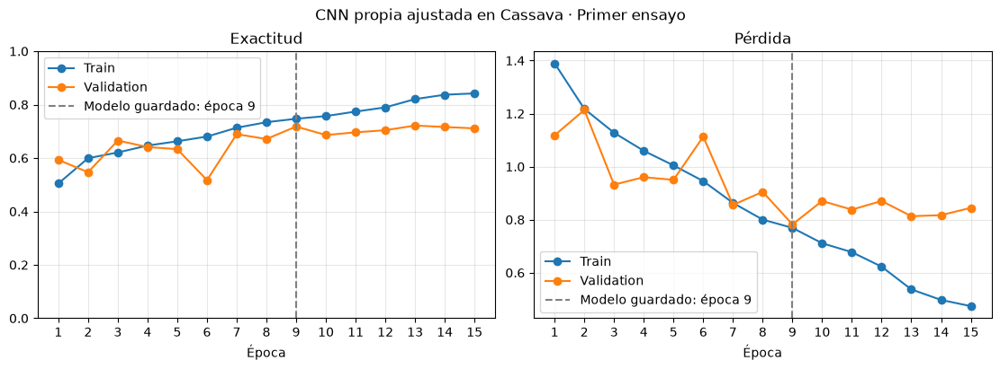

Máximo configurado: 30 épocas
Épocas ejecutadas: 15
Época seleccionada por menor val_loss: 9
Curvas guardadas en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_01_20261120_001728_038642\curvas_entrenamiento.png


In [16]:
# PASO 12: Mostrar las curvas de la primera corrida ajustada.
epocas_grafica = [
    int(registro["epoch"]) + 1
    for registro in registros_ajustada
]

fig_curvas, ejes = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained"
)
fig_curvas.suptitle("CNN propia ajustada en Cassava · Primer ensayo")

for eje, metrica, titulo in zip(
    ejes,
    ("accuracy", "loss"),
    ("Exactitud", "Pérdida"),
):
    valores_train = [
        float(registro[metrica])
        for registro in registros_ajustada
    ]
    valores_val = [
        float(registro[f"val_{metrica}"])
        for registro in registros_ajustada
    ]

    eje.plot(
        epocas_grafica, valores_train,
        marker="o", label="Train",
    )
    eje.plot(
        epocas_grafica, valores_val,
        marker="o", label="Validation",
    )
    eje.axvline(
        epoca_evaluada,
        color="gray",
        linestyle="--",
        label=f"Modelo guardado: época {epoca_evaluada}",
    )
    eje.set(
        title=titulo,
        xlabel="Época",
        xticks=epocas_grafica,
    )
    eje.grid(alpha=0.3)
    eje.legend()

ejes[0].set_ylim(0, 1)

ruta_curvas = carpeta_evaluacion / "curvas_entrenamiento.png"
fig_curvas.savefig(ruta_curvas, dpi=200)
plt.show()
plt.close(fig_curvas)

print(f"Máximo configurado: 30 épocas")
print(f"Épocas ejecutadas: {len(registros_ajustada)}")
print(f"Época seleccionada por menor val_loss: {epoca_evaluada}")
print("Curvas guardadas en:", ruta_curvas.resolve())

In [17]:
# PASO 13: Construir el modelo del segundo ensayo con pesos nuevos.
keras.backend.clear_session()
keras.utils.set_random_seed(42)

# Crear primero la misma arquitectura utilizada en el ensayo anterior.
nucleo_02 = construir_cnn_ajustada(IMG_SIZE, len(clases))

# Añadir el volteo como parte del modelo.
# Keras lo activa durante fit y lo desactiva durante la validación.
entrada_02 = keras.Input(
    shape=(*IMG_SIZE, 3),
    name="imagen_rgb_ensayo_02",
)
imagen_aumentada_02 = layers.RandomFlip(
    mode="horizontal",
    seed=43,
    name="volteo_solo_train",
)(entrada_02)

salida_02 = nucleo_02(imagen_aumentada_02)
modelo_02 = keras.Model(
    entrada_02,
    salida_02,
    name="cnn_ajustada_volteo",
)

# Mostrar las capas antes de configurar e iniciar el entrenamiento.
modelo_02.summary(expand_nested=True)

Model: "cnn_ajustada_volteo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb_ensayo_02            │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ volteo_solo_train (RandomFlip)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_propia_ajustada             │ (None, 5)              │       365,953 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ imagen_rgb (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ normalizacion (Rescaling)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d (Conv2D)            │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization        │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_1 (Conv2D)          │ (None, 56, 56, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_1      │ (None, 56, 56, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu_1 (ReLU)             │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_2 (Conv2D)          │ (None, 56, 56, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_2      │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu_2 (ReLU)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ depthwise_conv2d           │ (None, 56, 56, 64)     │           576 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_3      │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu_3 (ReLU)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ global_average_pooling2d   │ (None, 1, 1, 64)       │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_3 (Conv2D)          │ (None, 1, 1, 16)       │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_4 (Conv2D)          │ (None, 1, 1, 64)       │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ multiply (Multiply)        │ (None, 56, 56, 64)     │             

 Total params: 365,953 (1.40 MB)

 Trainable params: 359,313 (1.37 MB)

 Non-trainable params: 6,640 (25.94 KB)

In [18]:
# PASO 14: Configuración del segundo ensayo.
EPOCAS_MAXIMAS_02 = 20
TASA_INICIAL_02 = 0.0003
PACIENCIA_02 = 6

# Usar la misma fórmula de ponderación del primer ensayo.
conteos_train_02 = np.asarray(conteos["Train"], dtype=np.float64)

if (
    len(conteos_train_02) != len(clases)
    or np.any(conteos_train_02 <= 0)
):
    raise ValueError("Revisa los conteos de Train y el orden de las clases.")

pesos_02 = 1.0 / np.sqrt(conteos_train_02)
pesos_02 /= np.average(pesos_02, weights=conteos_train_02)
pesos_clase_02 = {
    indice: float(peso)
    for indice, peso in enumerate(pesos_02)
}

modelo_02.compile(
    optimizer=keras.optimizers.Adam(learning_rate=TASA_INICIAL_02),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Aplicar el procedimiento de preparación definido en el Paso 5.
train_02 = preparar_dataset(ds_train, entrenamiento=True)

print("Segundo ensayo: CNN ajustada con volteo horizontal")
print(f"Máximo de épocas: {EPOCAS_MAXIMAS_02}")
print(f"Tasa de aprendizaje inicial: {TASA_INICIAL_02}")
print(f"Paciencia de parada temprana: {PACIENCIA_02}")
print(f"Tamaño de imagen: {IMG_SIZE}")
print(f"Tamaño de lote: {BATCH_SIZE}")
print("Optimizador: Adam")
print("Pérdida: SparseCategoricalCrossentropy")
print("Modelo guardado según: menor val_loss")
print("Aumento durante entrenamiento: volteo horizontal aleatorio")

print("\nClase       Fotos     Peso")
for i, nombre in enumerate(clases):
    print(
        f"{nombre:<10} {int(conteos_train_02[i]):>5}"
        f" {pesos_clase_02[i]:>8.2f}"
    )

Segundo ensayo: CNN ajustada con volteo horizontal
Máximo de épocas: 20
Tasa de aprendizaje inicial: 0.0003
Paciencia de parada temprana: 6
Tamaño de imagen: (224, 224)
Tamaño de lote: 32
Optimizador: Adam
Pérdida: SparseCategoricalCrossentropy
Modelo guardado según: menor val_loss
Aumento durante entrenamiento: volteo horizontal aleatorio

Clase       Fotos     Peso
cbb          466     1.67
cbsd        1443     0.95
cgm          773     1.30
cmd         2658     0.70
healthy      316     2.03


In [19]:
# PASO 15: Entrenar y guardar el segundo ensayo en su propia carpeta.
actual_02 = Path.cwd()
cassava_02 = (
    actual_02
    if actual_02.name.lower() == "cassava"
    else actual_02 / "cassava"
)

if not (cassava_02 / "CNN_Propia_ajustada.ipynb").is_file():
    raise FileNotFoundError(
        "Ejecuta desde la carpeta BeanCass AI o desde su carpeta cassava."
    )

nombre_02 = datetime.now().strftime(
    "ensayo_02_volteo_%Y%m%d_%H%M%S_%f"
)
carpeta_corrida_02 = (
    cassava_02 / "resultados" / "cnn_propia_ajustada" / nombre_02
)
carpeta_corrida_02.mkdir(parents=True, exist_ok=False)
ruta_modelo_02 = carpeta_corrida_02 / "mejor_modelo.keras"

callbacks_02 = [
    # Registrar los resultados de cada época.
    keras.callbacks.CSVLogger(
        str(carpeta_corrida_02 / "historial.csv")
    ),
    # Conservar el modelo con menor pérdida de validación.
    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_modelo_02),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    ),
    # Reducir la tasa si la pérdida de validación se estanca.
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1,
    ),
    # Finalizar después de varias épocas sin una nueva mejora.
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PACIENCIA_02,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.TerminateOnNaN(),
]

print("Resultados de esta corrida:", carpeta_corrida_02.resolve())
inicio_02 = perf_counter()

historial_02 = modelo_02.fit(
    train_02,
    validation_data=val_preparado,
    class_weight=pesos_clase_02,
    epochs=EPOCAS_MAXIMAS_02,
    shuffle=False,
    callbacks=callbacks_02,
    verbose=1,
)

duracion_02 = perf_counter() - inicio_02
mejor_indice_02 = int(np.argmin(historial_02.history["val_loss"]))

print(f"\nÉpocas ejecutadas: {len(historial_02.history['loss'])}")
print(f"Época guardada: {mejor_indice_02 + 1}")
print(
    "Exactitud en validación: "
    f"{historial_02.history['val_accuracy'][mejor_indice_02]:.2%}"
)
print(
    "Pérdida en validación: "
    f"{historial_02.history['val_loss'][mejor_indice_02]:.4f}"
)
print(f"Tiempo de entrenamiento: {duracion_02 / 60:.2f} minutos")
print("Archivos guardados en:", carpeta_corrida_02.resolve())

Resultados de esta corrida: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_02_volteo_20261120_012104_032032
Epoch 1/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 180s 873ms/step - accuracy: 0.5134 - loss: 1.3899 - val_accuracy: 0.6204 - val_loss: 1.1060 - learning_rate: 3.0000e-04
Epoch 2/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 148s 832ms/step - accuracy: 0.5964 - loss: 1.2152 - val_accuracy: 0.6390 - val_loss: 1.0358 - learning_rate: 3.0000e-04
Epoch 3/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 139s 780ms/step - accuracy: 0.6275 - loss: 1.1180 - val_accuracy: 0.6718 - val_loss: 0.9100 - learning_rate: 3.0000e-04
Epoch 4/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 135s 758ms/step - accuracy: 0.6551 - loss: 1.0530 - val_accuracy: 0.6845 - val_loss: 0.8611 - learning_rate: 3.0000e-04
Epoch 5/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 134s 755ms/step - accuracy: 0.6646 - loss: 1.0039 - val_accuracy: 0.6998 - val_loss: 0.8293 - learning_rate: 3.0000e-04


Épocas ejecutadas: 20
Época guardada y evaluada: 18
Imágenes de validación: 1889
Exactitud en validación: 75.54%
F1 macro: 0.6797

Clase    Aciertos    Precisión   Recall       F1
cbb        92/156      55.42%    58.97%   0.5714
cbsd      352/482      77.88%    73.03%   0.7537
cgm       162/258      58.06%    62.79%   0.6034
cmd       752/887      86.04%    84.78%   0.8541
healthy    69/106      58.47%    65.09%   0.6161

cgm → cmd: 52
healthy → cmd: 12
Hojas enfermas predichas como sanas: 49


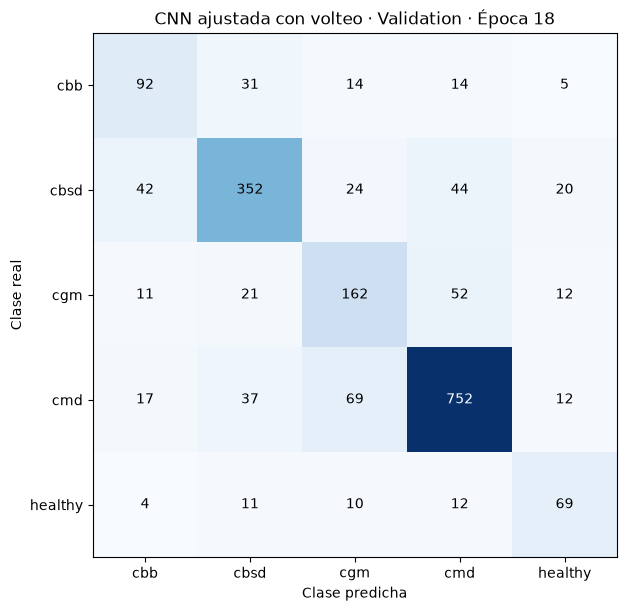


Matriz y reporte guardados en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_02_volteo_20261120_012104_032032


In [20]:
# Evaluar el modelo guardado del segundo ensayo con volteo horizontal.
actual = Path.cwd()
cassava = actual if actual.name.lower() == "cassava" else actual / "cassava"

carpeta_evaluacion_02 = (
    cassava
    / "resultados"
    / "cnn_propia_ajustada"
    / "ensayo_02_volteo_20261120_012104_032032"
)

# Leer el historial e identificar la época con menor pérdida de validación.
with (carpeta_evaluacion_02 / "historial.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    registros_eval_02 = list(csv.DictReader(archivo))

mejor_registro_02 = min(
    registros_eval_02,
    key=lambda registro: float(registro["val_loss"]),
)
epoca_evaluada_02 = int(mejor_registro_02["epoch"]) + 1

# Cargar el modelo seleccionado y contar sus predicciones en Validation.
modelo_evaluado_02 = keras.models.load_model(
    carpeta_evaluacion_02 / "mejor_modelo.keras",
    compile=False,
)

nombres_02 = list(clases)
matriz_02 = np.zeros((len(nombres_02), len(nombres_02)), dtype=int)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_evaluado_02(imagenes, training=False).numpy()
    predicciones = np.argmax(probabilidades, axis=1)
    etiquetas_reales = etiquetas.numpy().astype(int)
    np.add.at(matriz_02, (etiquetas_reales, predicciones), 1)

# Comprobar que se evaluó toda la partición de validación.
total_evaluado_02 = int(matriz_02.sum())
total_esperado_02 = info.splits["validation"].num_examples

if total_evaluado_02 != total_esperado_02:
    raise ValueError(
        f"Se evaluaron {total_evaluado_02} imágenes; "
        f"se esperaban {total_esperado_02}."
    )

# Calcular exactitud, precisión, recall y F1.
aciertos_eval_02 = matriz_02.diagonal()
reales_eval_02 = matriz_02.sum(axis=1)
predichas_eval_02 = matriz_02.sum(axis=0)

precision_eval_02 = aciertos_eval_02 / np.maximum(predichas_eval_02, 1)
recall_eval_02 = aciertos_eval_02 / np.maximum(reales_eval_02, 1)
f1_eval_02 = (
    2 * aciertos_eval_02
    / np.maximum(reales_eval_02 + predichas_eval_02, 1)
)
exactitud_eval_02 = aciertos_eval_02.sum() / total_evaluado_02

print(f"Épocas ejecutadas: {len(registros_eval_02)}")
print(f"Época guardada y evaluada: {epoca_evaluada_02}")
print(f"Imágenes de validación: {total_evaluado_02}")
print(f"Exactitud en validación: {exactitud_eval_02:.2%}")
print(f"F1 macro: {f1_eval_02.mean():.4f}")

print("\nClase    Aciertos    Precisión   Recall       F1")
for i, nombre in enumerate(nombres_02):
    correctas = f"{aciertos_eval_02[i]}/{reales_eval_02[i]}"
    print(
        f"{nombre:<8} {correctas:>8}"
        f" {precision_eval_02[i]:>11.2%}"
        f" {recall_eval_02[i]:>9.2%}"
        f" {f1_eval_02[i]:>8.4f}"
    )

# Revisar las confusiones que aparecieron en el primer ensayo.
indice_cgm_02 = nombres_02.index("cgm")
indice_cmd_02 = nombres_02.index("cmd")
indice_healthy_02 = nombres_02.index("healthy")

enfermas_como_sanas_02 = (
    matriz_02[:, indice_healthy_02].sum()
    - matriz_02[indice_healthy_02, indice_healthy_02]
)

print(f"\ncgm → cmd: {matriz_02[indice_cgm_02, indice_cmd_02]}")
print(f"healthy → cmd: {matriz_02[indice_healthy_02, indice_cmd_02]}")
print(f"Hojas enfermas predichas como sanas: {enfermas_como_sanas_02}")

# Guardar la matriz numérica.
with (carpeta_evaluacion_02 / "matriz_confusion_validation.csv").open(
    "w", encoding="utf-8", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(["real/predicha", *nombres_02])
    for nombre, fila in zip(nombres_02, matriz_02):
        escritor.writerow([nombre, *fila])

# Guardar las métricas de cada clase.
with (carpeta_evaluacion_02 / "reporte_validation.csv").open(
    "w", encoding="utf-8", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(
        ["clase", "aciertos", "total_real", "precision", "recall", "f1"]
    )
    for i, nombre in enumerate(nombres_02):
        escritor.writerow([
            nombre,
            aciertos_eval_02[i],
            reales_eval_02[i],
            precision_eval_02[i],
            recall_eval_02[i],
            f1_eval_02[i],
        ])

# Mostrar la matriz: filas reales y columnas predichas.
fig_matriz_02, eje = plt.subplots(
    figsize=(7, 6), layout="constrained"
)
eje.imshow(matriz_02, cmap="Blues")
eje.set_xticks(range(len(nombres_02)), labels=nombres_02)
eje.set_yticks(range(len(nombres_02)), labels=nombres_02)
eje.set(
    title=f"CNN ajustada con volteo · Validation · Época {epoca_evaluada_02}",
    xlabel="Clase predicha",
    ylabel="Clase real",
)

for fila, columna in np.ndindex(matriz_02.shape):
    valor = matriz_02[fila, columna]
    color = "white" if valor > matriz_02.max() / 2 else "black"
    eje.text(
        columna, fila, str(valor),
        ha="center", va="center", color=color,
    )

fig_matriz_02.savefig(
    carpeta_evaluacion_02 / "matriz_confusion_validation.png",
    dpi=200,
)
plt.show()
plt.close(fig_matriz_02)

print("\nMatriz y reporte guardados en:", carpeta_evaluacion_02.resolve())

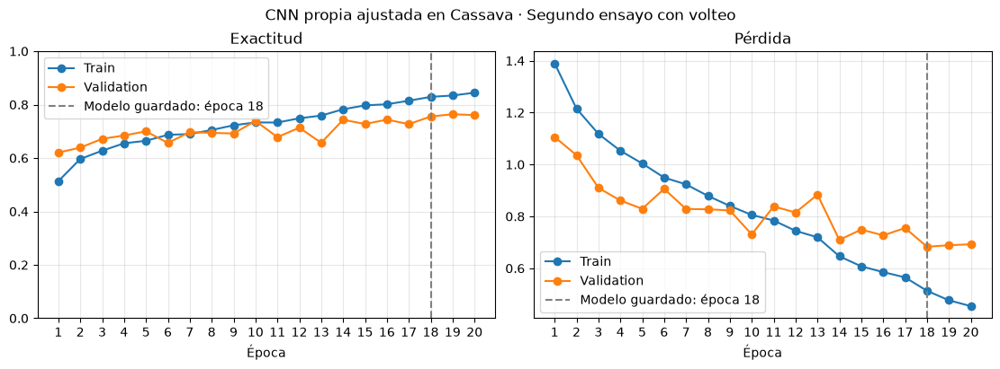

Máximo configurado: 20 épocas
Épocas ejecutadas: 20
Época seleccionada por menor val_loss: 18
Curvas guardadas en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_02_volteo_20261120_012104_032032\curvas_entrenamiento.png


In [21]:
# Graficar el historial del segundo ensayo.
epocas_eval_02 = [
    int(registro["epoch"]) + 1
    for registro in registros_eval_02
]

fig_curvas_02, ejes = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained"
)
fig_curvas_02.suptitle(
    "CNN propia ajustada en Cassava · Segundo ensayo con volteo"
)

for eje, metrica, titulo in zip(
    ejes,
    ("accuracy", "loss"),
    ("Exactitud", "Pérdida"),
):
    valores_train = [
        float(registro[metrica])
        for registro in registros_eval_02
    ]
    valores_val = [
        float(registro[f"val_{metrica}"])
        for registro in registros_eval_02
    ]

    eje.plot(
        epocas_eval_02, valores_train,
        marker="o", label="Train",
    )
    eje.plot(
        epocas_eval_02, valores_val,
        marker="o", label="Validation",
    )
    eje.axvline(
        epoca_evaluada_02,
        color="gray",
        linestyle="--",
        label=f"Modelo guardado: época {epoca_evaluada_02}",
    )
    eje.set(
        title=titulo,
        xlabel="Época",
        xticks=epocas_eval_02,
    )
    eje.grid(alpha=0.3)
    eje.legend()

ejes[0].set_ylim(0, 1)

ruta_curvas_02 = carpeta_evaluacion_02 / "curvas_entrenamiento.png"
fig_curvas_02.savefig(ruta_curvas_02, dpi=200)
plt.show()
plt.close(fig_curvas_02)

print("Máximo configurado: 20 épocas")
print(f"Épocas ejecutadas: {len(registros_eval_02)}")
print(f"Época seleccionada por menor val_loss: {epoca_evaluada_02}")
print("Curvas guardadas en:", ruta_curvas_02.resolve())

In [19]:
# PASO 18: Construir la CNN del tercer ensayo con dropout de 0.40.
# Reutilizar los bloques definidos en el Paso 9.

def construir_cnn_03(tamano_imagen, numero_clases):
    entrada = keras.Input(
        shape=(*tamano_imagen, 3),
        name="imagen_rgb",
    )
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(entrada)

    # Características iniciales.
    x = convolucion_inicial(x, 32, 3, paso=2)
    x = convolucion_inicial(x, 32, 3, paso=2)

    # Grupos ligeros con atención y conexiones densas.
    configuracion_grupos = [
        (16, 48),
        (24, 80),
        (32, 128),
    ]

    for indice, (crecimiento, canales_salida) in enumerate(configuracion_grupos):
        for _ in range(3):
            x = bloque_ligero_denso(x, crecimiento)

        x = convolucion_inicial(x, canales_salida, 1)

        if indice < len(configuracion_grupos) - 1:
            x = layers.AveragePooling2D(2)(x)

    x = layers.GlobalAveragePooling2D(name="resumen_global")(x)

    # Cambio de este ensayo: aumentar dropout de 0.30 a 0.40.
    x = layers.Dropout(0.40, name="regularizacion")(x)

    salida = layers.Dense(
        numero_clases,
        activation="softmax",
        name="clasificacion",
    )(x)

    return keras.Model(
        entrada,
        salida,
        name="cnn_propia_ajustada",
    )


# Iniciar con pesos nuevos.
keras.backend.clear_session()
keras.utils.set_random_seed(42)

nucleo_03 = construir_cnn_03(IMG_SIZE, len(clases))

# Mantener el volteo horizontal durante el entrenamiento.
entrada_03 = keras.Input(
    shape=(*IMG_SIZE, 3),
    name="imagen_rgb_ensayo_03",
)
imagen_aumentada_03 = layers.RandomFlip(
    mode="horizontal",
    seed=43,
    name="volteo_solo_train",
)(entrada_03)

salida_03 = nucleo_03(imagen_aumentada_03)
modelo_03 = keras.Model(
    entrada_03,
    salida_03,
    name="cnn_ajustada_volteo_dropout40",
)

modelo_03.summary(expand_nested=True)

Model: "cnn_ajustada_volteo_dropout40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb_ensayo_03            │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ volteo_solo_train (RandomFlip)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_propia_ajustada             │ (None, 5)              │       365,953 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ imagen_rgb (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ normalizacion (Rescaling)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d (Conv2D)            │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization        │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_1 (Conv2D)          │ (None, 56, 56, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_1      │ (None, 56, 56, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu_1 (ReLU)             │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_2 (Conv2D)          │ (None, 56, 56, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_2      │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu_2 (ReLU)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ depthwise_conv2d           │ (None, 56, 56, 64)     │           576 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ batch_normalization_3      │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ re_lu_3 (ReLU)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ global_average_pooling2d   │ (None, 1, 1, 64)       │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_3 (Conv2D)          │ (None, 1, 1, 16)       │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2d_4 (Conv2D)          │ (None, 1, 1, 64)       │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ multiply (Multiply)        │ (None, 56, 56, 64)     │             

 Total params: 365,953 (1.40 MB)

 Trainable params: 359,313 (1.37 MB)

 Non-trainable params: 6,640 (25.94 KB)

In [20]:
# PASO 19: Revisar la configuración del tercer ensayo.
EPOCAS_MAXIMAS_03 = 20
TASA_INICIAL_03 = 0.0003
PACIENCIA_03 = 6

# Calcular los mismos pesos de clase mediante los conteos de Train.
conteos_train_03 = np.asarray(conteos["Train"], dtype=np.float64)

if (
    len(conteos_train_03) != len(clases)
    or np.any(conteos_train_03 <= 0)
):
    raise ValueError("Revisa los conteos de Train y el orden de las clases.")

pesos_03 = 1.0 / np.sqrt(conteos_train_03)
pesos_03 /= np.average(pesos_03, weights=conteos_train_03)
pesos_clase_03 = {
    indice: float(peso)
    for indice, peso in enumerate(pesos_03)
}

modelo_03.compile(
    optimizer=keras.optimizers.Adam(learning_rate=TASA_INICIAL_03),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

train_03 = preparar_dataset(ds_train, entrenamiento=True)

print("Tercer ensayo: CNN ajustada con volteo y dropout de 0.40")
print(f"Máximo de épocas: {EPOCAS_MAXIMAS_03}")
print(f"Tasa de aprendizaje inicial: {TASA_INICIAL_03}")
print(f"Paciencia de parada temprana: {PACIENCIA_03}")
print(f"Tamaño de imagen: {IMG_SIZE}")
print(f"Tamaño de lote: {BATCH_SIZE}")
print("Optimizador: Adam")
print("Pérdida: SparseCategoricalCrossentropy")
print("Modelo guardado según: menor val_loss")
print("Aumento durante entrenamiento: volteo horizontal aleatorio")
print(f"Dropout: {nucleo_03.get_layer('regularizacion').rate:.2f}")

print("\nClase       Fotos     Peso")
for i, nombre in enumerate(clases):
    print(
        f"{nombre:<10} {int(conteos_train_03[i]):>5}"
        f" {pesos_clase_03[i]:>8.2f}"
    )

Tercer ensayo: CNN ajustada con volteo y dropout de 0.40
Máximo de épocas: 20
Tasa de aprendizaje inicial: 0.0003
Paciencia de parada temprana: 6
Tamaño de imagen: (224, 224)
Tamaño de lote: 32
Optimizador: Adam
Pérdida: SparseCategoricalCrossentropy
Modelo guardado según: menor val_loss
Aumento durante entrenamiento: volteo horizontal aleatorio
Dropout: 0.40

Clase       Fotos     Peso
cbb          466     1.67
cbsd        1443     0.95
cgm          773     1.30
cmd         2658     0.70
healthy      316     2.03


In [21]:
# PASO 20: Entrenar el tercer ensayo y guardar su mejor modelo.
actual_03 = Path.cwd()
cassava_03 = (
    actual_03
    if actual_03.name.lower() == "cassava"
    else actual_03 / "cassava"
)

if not (cassava_03 / "CNN_Propia_ajustada.ipynb").is_file():
    raise FileNotFoundError(
        "Ejecuta desde la carpeta BeanCass AI o desde su carpeta cassava."
    )

nombre_03 = datetime.now().strftime(
    "ensayo_03_dropout40_%Y%m%d_%H%M%S_%f"
)
carpeta_corrida_03 = (
    cassava_03 / "resultados" / "cnn_propia_ajustada" / nombre_03
)
carpeta_corrida_03.mkdir(parents=True, exist_ok=False)
ruta_modelo_03 = carpeta_corrida_03 / "mejor_modelo.keras"

callbacks_03 = [
    # Registrar las métricas de cada época.
    keras.callbacks.CSVLogger(
        str(carpeta_corrida_03 / "historial.csv")
    ),
    # Guardar la menor pérdida de validación.
    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_modelo_03),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    ),
    # Reducir la tasa cuando la validación se estanque.
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1,
    ),
    # Detener después de seis épocas sin una nueva menor val_loss.
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PACIENCIA_03,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.TerminateOnNaN(),
]

print("Resultados de esta corrida:", carpeta_corrida_03.resolve())
inicio_03 = perf_counter()

historial_03 = modelo_03.fit(
    train_03,
    validation_data=val_preparado,
    class_weight=pesos_clase_03,
    epochs=EPOCAS_MAXIMAS_03,
    shuffle=False,
    callbacks=callbacks_03,
    verbose=1,
)

duracion_03 = perf_counter() - inicio_03
mejor_indice_03 = int(np.argmin(historial_03.history["val_loss"]))

print(f"\nÉpocas ejecutadas: {len(historial_03.history['loss'])}")
print(f"Época guardada: {mejor_indice_03 + 1}")
print(
    "Exactitud en validación: "
    f"{historial_03.history['val_accuracy'][mejor_indice_03]:.2%}"
)
print(
    "Pérdida en validación: "
    f"{historial_03.history['val_loss'][mejor_indice_03]:.4f}"
)
print(f"Tiempo de entrenamiento: {duracion_03 / 60:.2f} minutos")
print("Archivos guardados en:", carpeta_corrida_03.resolve())

Resultados de esta corrida: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_03_dropout40_20261120_091855_945471
Epoch 1/20


177/177 ━━━━━━━━━━━━━━━━━━━━ 175s 843ms/step - accuracy: 0.4855 - loss: 1.4270 - val_accuracy: 0.6220 - val_loss: 1.0589 - learning_rate: 3.0000e-04
Epoch 2/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 145s 817ms/step - accuracy: 0.5748 - loss: 1.2505 - val_accuracy: 0.6300 - val_loss: 1.0467 - learning_rate: 3.0000e-04
Epoch 3/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 146s 820ms/step - accuracy: 0.6117 - loss: 1.1631 - val_accuracy: 0.6559 - val_loss: 0.9424 - learning_rate: 3.0000e-04
Epoch 4/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 142s 798ms/step - accuracy: 0.6411 - loss: 1.0986 - val_accuracy: 0.6623 - val_loss: 0.9447 - learning_rate: 3.0000e-04
Epoch 5/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 131s 737ms/step - accuracy: 0.6535 - loss: 1.0439 - val_accuracy: 0.6390 - val_loss: 0.9583 - learning_rate: 3.0000e-04
Epoch 6/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 131s 737ms/step - accuracy: 0.6715 - loss: 0.9898 - val_accuracy: 0.6543 - val_loss: 0.9234 - learning_rate: 3.0000e-04
Epoch 7/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 131s 739ms/

Épocas ejecutadas: 20
Época guardada y evaluada: 18
Imágenes de validación: 1889
Exactitud en validación: 73.48%
F1 macro: 0.6542

Clase    Aciertos    Precisión   Recall       F1
cbb        89/156      58.94%    57.05%   0.5798
cbsd      333/482      78.17%    69.09%   0.7335
cgm       164/258      48.09%    63.57%   0.5476
cmd       745/887      85.14%    83.99%   0.8456
healthy    57/106      59.38%    53.77%   0.5644

cbb → cbsd: 24
cbsd → cmd: 53
cgm → cmd: 56
cmd → cgm: 88
healthy → cmd: 7
Hojas enfermas predichas como sanas: 39


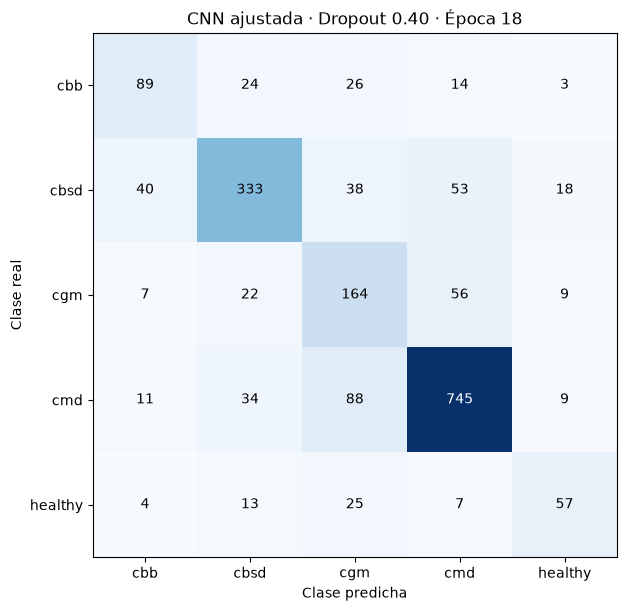


Matriz y reporte guardados en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_03_dropout40_20261120_091855_945471


In [22]:
# Evaluar el tercer ensayo completo con dropout de 0.40.
actual = Path.cwd()
cassava = actual if actual.name.lower() == "cassava" else actual / "cassava"

carpeta_evaluacion_03 = (
    cassava
    / "resultados"
    / "cnn_propia_ajustada"
    / "ensayo_03_dropout40_20261120_091855_945471"
)

# Identificar la época seleccionada por menor pérdida de validación.
with (carpeta_evaluacion_03 / "historial.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    registros_eval_03 = list(csv.DictReader(archivo))

mejor_registro_eval_03 = min(
    registros_eval_03,
    key=lambda registro: float(registro["val_loss"]),
)
epoca_evaluada_03 = int(mejor_registro_eval_03["epoch"]) + 1

# Cargar el modelo guardado y contar las predicciones de Validation.
modelo_evaluado_03 = keras.models.load_model(
    carpeta_evaluacion_03 / "mejor_modelo.keras",
    compile=False,
)

nombres_03 = list(clases)
matriz_03 = np.zeros((len(nombres_03), len(nombres_03)), dtype=int)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_evaluado_03(imagenes, training=False).numpy()
    predicciones = np.argmax(probabilidades, axis=1)
    etiquetas_reales = etiquetas.numpy().astype(int)
    np.add.at(matriz_03, (etiquetas_reales, predicciones), 1)

# Comprobar que se evaluó toda la partición.
total_evaluado_03 = int(matriz_03.sum())
total_esperado_03 = info.splits["validation"].num_examples

if total_evaluado_03 != total_esperado_03:
    raise ValueError(
        f"Se evaluaron {total_evaluado_03} imágenes; "
        f"se esperaban {total_esperado_03}."
    )

# Calcular exactitud, precisión, recall y F1.
aciertos_eval_03 = matriz_03.diagonal()
reales_eval_03 = matriz_03.sum(axis=1)
predichas_eval_03 = matriz_03.sum(axis=0)

precision_eval_03 = aciertos_eval_03 / np.maximum(predichas_eval_03, 1)
recall_eval_03 = aciertos_eval_03 / np.maximum(reales_eval_03, 1)
f1_eval_03 = (
    2 * aciertos_eval_03
    / np.maximum(reales_eval_03 + predichas_eval_03, 1)
)
exactitud_eval_03 = aciertos_eval_03.sum() / total_evaluado_03

print(f"Épocas ejecutadas: {len(registros_eval_03)}")
print(f"Época guardada y evaluada: {epoca_evaluada_03}")
print(f"Imágenes de validación: {total_evaluado_03}")
print(f"Exactitud en validación: {exactitud_eval_03:.2%}")
print(f"F1 macro: {f1_eval_03.mean():.4f}")

print("\nClase    Aciertos    Precisión   Recall       F1")
for i, nombre in enumerate(nombres_03):
    correctas = f"{aciertos_eval_03[i]}/{reales_eval_03[i]}"
    print(
        f"{nombre:<8} {correctas:>8}"
        f" {precision_eval_03[i]:>11.2%}"
        f" {recall_eval_03[i]:>9.2%}"
        f" {f1_eval_03[i]:>8.4f}"
    )

# Revisar confusiones concretas de los ensayos anteriores.
indice_cbb_03 = nombres_03.index("cbb")
indice_cbsd_03 = nombres_03.index("cbsd")
indice_cgm_03 = nombres_03.index("cgm")
indice_cmd_03 = nombres_03.index("cmd")
indice_healthy_03 = nombres_03.index("healthy")

enfermas_como_sanas_03 = (
    matriz_03[:, indice_healthy_03].sum()
    - matriz_03[indice_healthy_03, indice_healthy_03]
)

print(f"\ncbb → cbsd: {matriz_03[indice_cbb_03, indice_cbsd_03]}")
print(f"cbsd → cmd: {matriz_03[indice_cbsd_03, indice_cmd_03]}")
print(f"cgm → cmd: {matriz_03[indice_cgm_03, indice_cmd_03]}")
print(f"cmd → cgm: {matriz_03[indice_cmd_03, indice_cgm_03]}")
print(f"healthy → cmd: {matriz_03[indice_healthy_03, indice_cmd_03]}")
print(f"Hojas enfermas predichas como sanas: {enfermas_como_sanas_03}")

# Guardar la matriz numérica.
with (carpeta_evaluacion_03 / "matriz_confusion_validation.csv").open(
    "w", encoding="utf-8", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(["real/predicha", *nombres_03])
    for nombre, fila in zip(nombres_03, matriz_03):
        escritor.writerow([nombre, *fila])

# Guardar el reporte de las cinco clases.
with (carpeta_evaluacion_03 / "reporte_validation.csv").open(
    "w", encoding="utf-8", newline=""
) as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(
        ["clase", "aciertos", "total_real", "precision", "recall", "f1"]
    )
    for i, nombre in enumerate(nombres_03):
        escritor.writerow([
            nombre,
            aciertos_eval_03[i],
            reales_eval_03[i],
            precision_eval_03[i],
            recall_eval_03[i],
            f1_eval_03[i],
        ])

# Dibujar la matriz con filas reales y columnas predichas.
fig_matriz_03, eje = plt.subplots(
    figsize=(7, 6), layout="constrained"
)
eje.imshow(matriz_03, cmap="Blues")
eje.set_xticks(range(len(nombres_03)), labels=nombres_03)
eje.set_yticks(range(len(nombres_03)), labels=nombres_03)
eje.set(
    title=f"CNN ajustada · Dropout 0.40 · Época {epoca_evaluada_03}",
    xlabel="Clase predicha",
    ylabel="Clase real",
)

for fila, columna in np.ndindex(matriz_03.shape):
    valor = matriz_03[fila, columna]
    color = "white" if valor > matriz_03.max() / 2 else "black"
    eje.text(
        columna, fila, str(valor),
        ha="center", va="center", color=color,
    )

fig_matriz_03.savefig(
    carpeta_evaluacion_03 / "matriz_confusion_validation.png",
    dpi=200,
)
plt.show()
plt.close(fig_matriz_03)

print("\nMatriz y reporte guardados en:", carpeta_evaluacion_03.resolve())

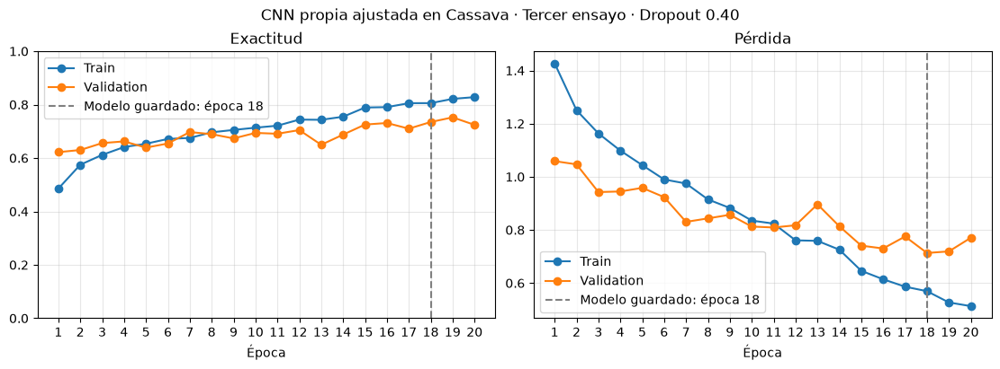

Máximo configurado: 20 épocas
Épocas ejecutadas: 20
Época seleccionada por menor val_loss: 18
Curvas guardadas en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_03_dropout40_20261120_091855_945471\curvas_entrenamiento.png


In [23]:
# Graficar el historial del tercer ensayo completo.
epocas_eval_03 = [
    int(registro["epoch"]) + 1
    for registro in registros_eval_03
]

fig_curvas_03, ejes = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained"
)
fig_curvas_03.suptitle(
    "CNN propia ajustada en Cassava · Tercer ensayo · Dropout 0.40"
)

for eje, metrica, titulo in zip(
    ejes,
    ("accuracy", "loss"),
    ("Exactitud", "Pérdida"),
):
    valores_train = [
        float(registro[metrica])
        for registro in registros_eval_03
    ]
    valores_val = [
        float(registro[f"val_{metrica}"])
        for registro in registros_eval_03
    ]

    eje.plot(
        epocas_eval_03, valores_train,
        marker="o", label="Train",
    )
    eje.plot(
        epocas_eval_03, valores_val,
        marker="o", label="Validation",
    )
    eje.axvline(
        epoca_evaluada_03,
        color="gray",
        linestyle="--",
        label=f"Modelo guardado: época {epoca_evaluada_03}",
    )
    eje.set(
        title=titulo,
        xlabel="Época",
        xticks=epocas_eval_03,
    )
    eje.grid(alpha=0.3)
    eje.legend()

ejes[0].set_ylim(0, 1)

ruta_curvas_03 = carpeta_evaluacion_03 / "curvas_entrenamiento.png"
fig_curvas_03.savefig(ruta_curvas_03, dpi=200)
plt.show()
plt.close(fig_curvas_03)

print("Máximo configurado: 20 épocas")
print(f"Épocas ejecutadas: {len(registros_eval_03)}")
print(f"Época seleccionada por menor val_loss: {epoca_evaluada_03}")
print("Curvas guardadas en:", ruta_curvas_03.resolve())

In [24]:
# Comparar los tres modelos guardados sobre las mismas imágenes.
actual = Path.cwd()
cassava = actual if actual.name.lower() == "cassava" else actual / "cassava"
resultados_revision = cassava / "resultados" / "cnn_propia_ajustada"

carpetas_revision = {
    "ensayo_01": "ensayo_01_20261120_001728_038642",
    "ensayo_02": "ensayo_02_volteo_20261120_012104_032032",
    "ensayo_03": "ensayo_03_dropout40_20261120_091855_945471",
}

nombres_revision = list(info.features["label"].names)
modelos_revision = {}

for ensayo, carpeta in carpetas_revision.items():
    ruta = resultados_revision / carpeta / "mejor_modelo.keras"
    modelos_revision[ensayo] = keras.models.load_model(
        ruta, compile=False
    )
    print(f"Modelo cargado: {ensayo}")


# Conservar el identificador de cada imagen al preparar los lotes.
def preparar_para_revision(registro):
    imagen, etiqueta = preparar_imagen(registro)
    return imagen, etiqueta, registro["image/filename"]


datos_revision = (
    ds_val.map(
        preparar_para_revision,
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

filas_revision = []

for numero_lote, (imagenes, etiquetas, archivos) in enumerate(datos_revision):
    etiquetas_lote = etiquetas.numpy().astype(int)
    archivos_lote = archivos.numpy()

    # Obtener las puntuaciones de los tres ensayos para este lote.
    probabilidades_lote = {
        ensayo: modelo(imagenes, training=False).numpy()
        for ensayo, modelo in modelos_revision.items()
    }

    for posicion, etiqueta_real in enumerate(etiquetas_lote):
        fila = {
            "indice": len(filas_revision),
            "archivo": archivos_lote[posicion].decode("utf-8"),
            "real": nombres_revision[etiqueta_real],
        }

        for ensayo, probabilidades in probabilidades_lote.items():
            indice_predicho = int(np.argmax(probabilidades[posicion]))
            nombre_predicho = nombres_revision[indice_predicho]

            fila[f"pred_{ensayo}"] = nombre_predicho
            fila[f"puntuacion_{ensayo}"] = float(
                probabilidades[posicion, indice_predicho]
            )
            fila[f"acierto_{ensayo}"] = (
                nombre_predicho == fila["real"]
            )

        filas_revision.append(fila)

    if (numero_lote + 1) % 10 == 0:
        print(f"Imágenes revisadas: {len(filas_revision)}")

# Verificar que se incluyó toda la partición de validación.
esperadas_revision = info.splits["validation"].num_examples
if len(filas_revision) != esperadas_revision:
    raise ValueError(
        f"Se revisaron {len(filas_revision)} imágenes; "
        f"se esperaban {esperadas_revision}."
    )

# Guardar los resultados para identificar cada foto y sus predicciones.
carpeta_revision = resultados_revision / datetime.now().strftime(
    "revision_imagenes_%Y%m%d_%H%M%S_%f"
)
carpeta_revision.mkdir(parents=True, exist_ok=False)

ruta_predicciones_revision = carpeta_revision / "predicciones_tres_ensayos.csv"

with ruta_predicciones_revision.open(
    "w", encoding="utf-8", newline=""
) as archivo:
    escritor = csv.DictWriter(
        archivo, fieldnames=list(filas_revision[0].keys())
    )
    escritor.writeheader()
    escritor.writerows(filas_revision)

print(f"\nImágenes evaluadas: {len(filas_revision)}")
for ensayo in modelos_revision:
    aciertos = sum(
        fila[f"acierto_{ensayo}"]
        for fila in filas_revision
    )
    print(
        f"{ensayo}: {aciertos}/{len(filas_revision)} correctas"
        f" · {aciertos / len(filas_revision):.2%}"
    )

print("\nPredicciones guardadas en:", ruta_predicciones_revision.resolve())

Modelo cargado: ensayo_01
Modelo cargado: ensayo_02
Modelo cargado: ensayo_03
Imágenes revisadas: 320
Imágenes revisadas: 640
Imágenes revisadas: 960
Imágenes revisadas: 1280
Imágenes revisadas: 1600
Imágenes revisadas: 1889

Imágenes evaluadas: 1889
ensayo_01: 1356/1889 correctas · 71.78%
ensayo_02: 1427/1889 correctas · 75.54%
ensayo_03: 1388/1889 correctas · 73.48%

Predicciones guardadas en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\predicciones_tres_ensayos.csv


Ejemplo 1: validation-cbb-110.jpg
Ejemplo 2: validation-cbb-40.jpg


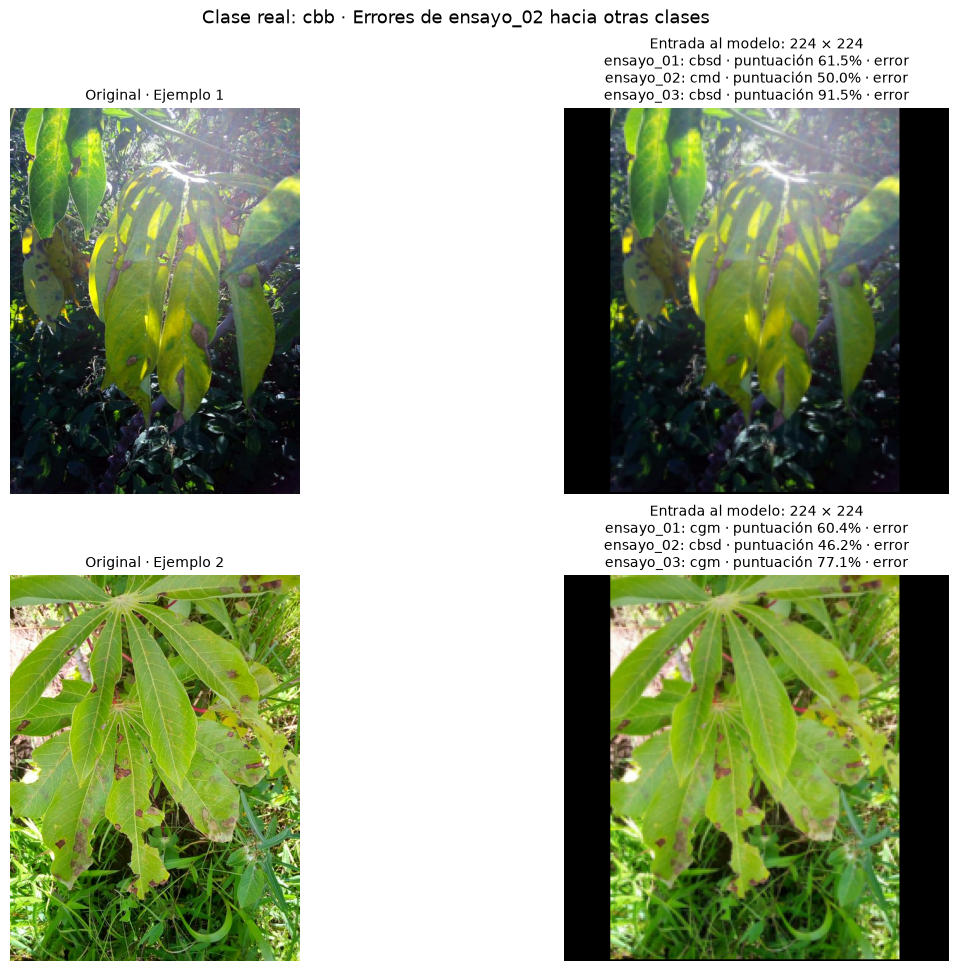

Errores encontrados con ese filtro: 64
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_02_cbb_a_otras_clases.png
Ejemplo 1: validation-cbsd-191.jpg
Ejemplo 2: validation-cbsd-226.jpg


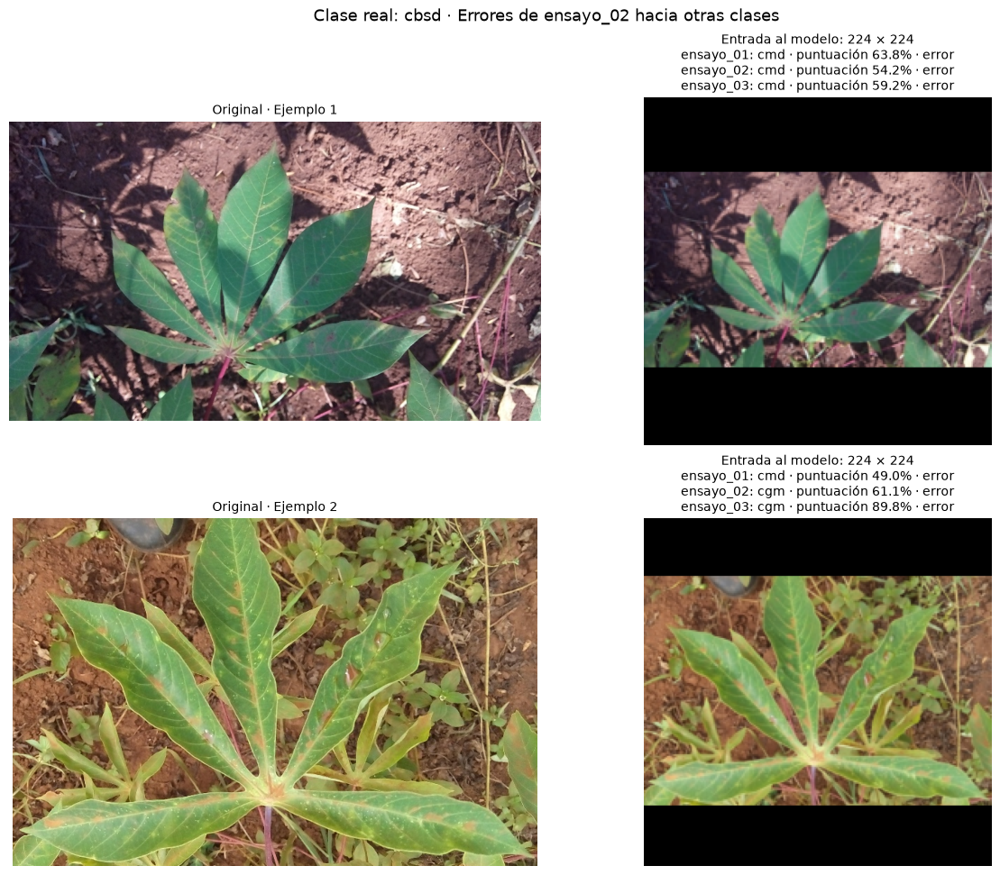

Errores encontrados con ese filtro: 130
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_02_cbsd_a_otras_clases.png
Ejemplo 1: validation-cgm-46.jpg
Ejemplo 2: validation-cgm-8.jpg


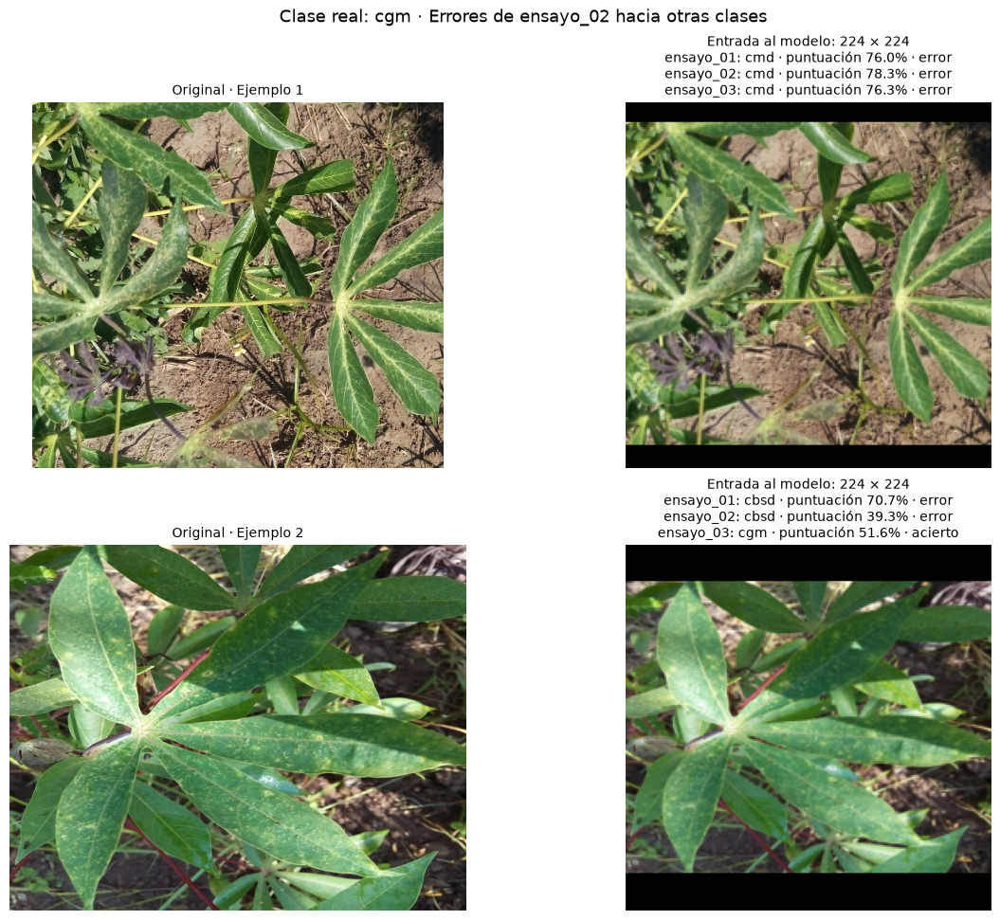

Errores encontrados con ese filtro: 96
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_02_cgm_a_otras_clases.png
Ejemplo 1: validation-cmd-67.jpg
Ejemplo 2: validation-cmd-55.jpg


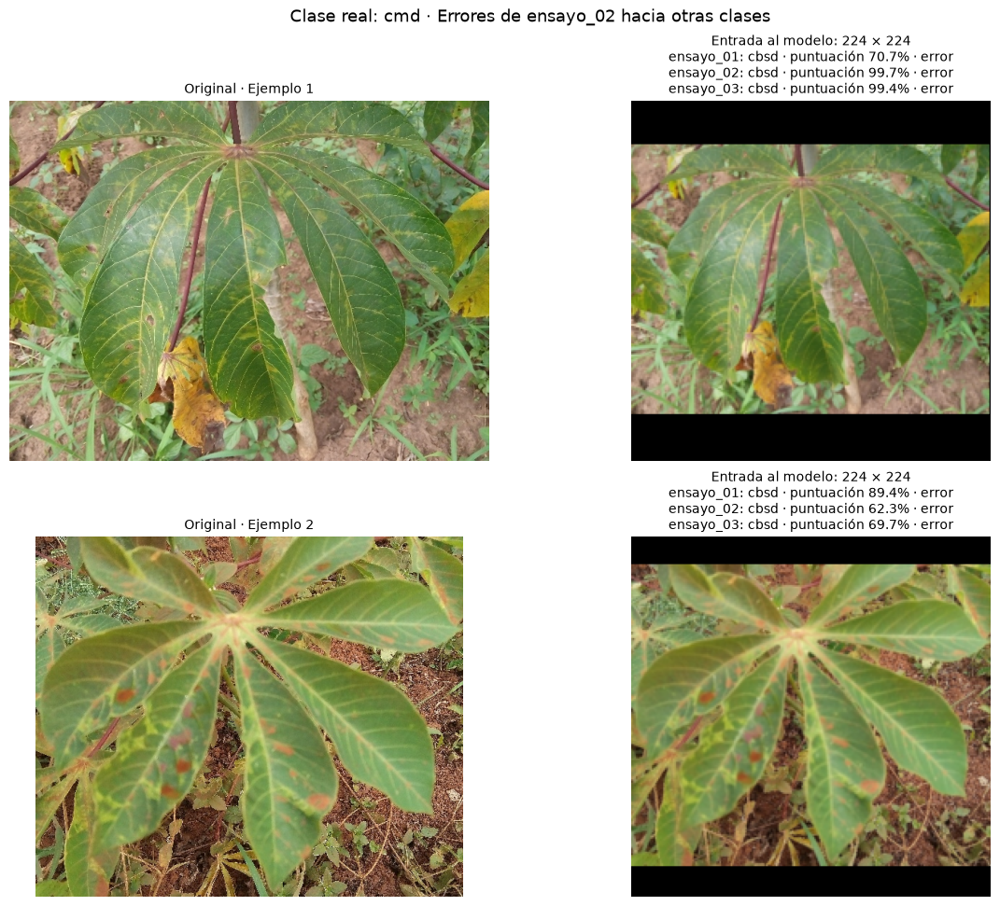

Errores encontrados con ese filtro: 135
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_02_cmd_a_otras_clases.png
Ejemplo 1: validation-healthy-43.jpg
Ejemplo 2: validation-healthy-75.jpg


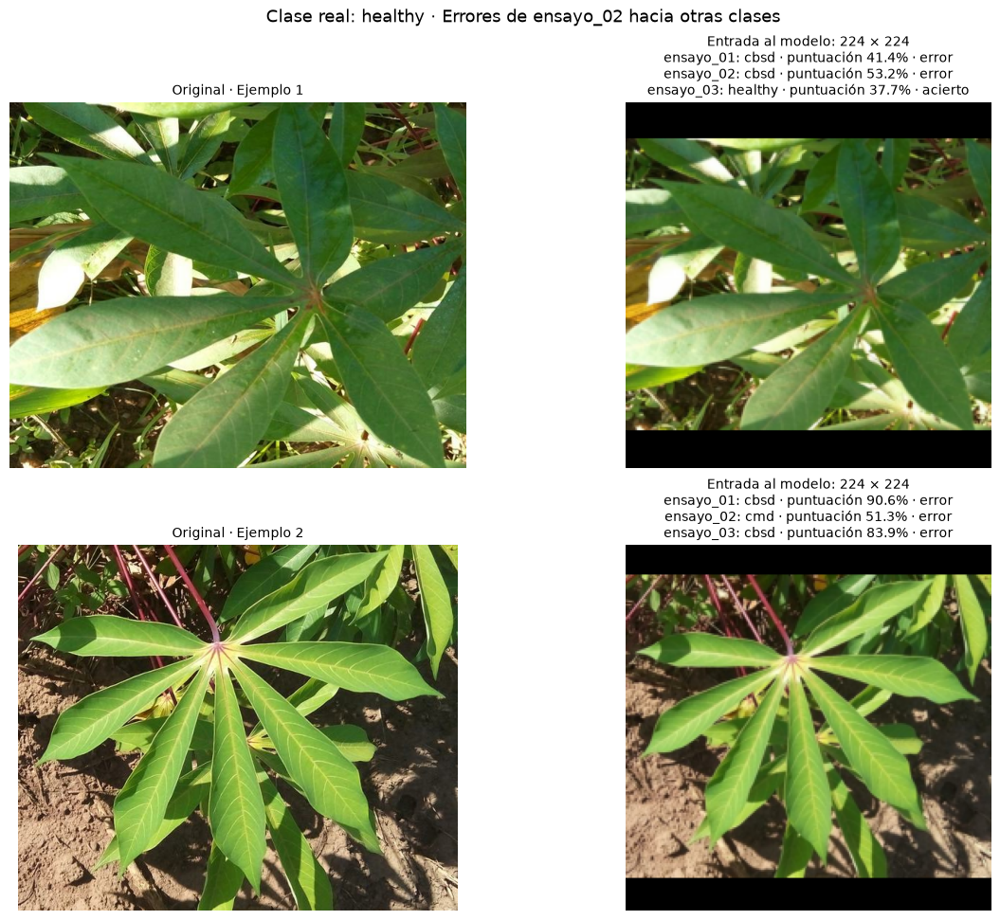

Errores encontrados con ese filtro: 37
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_02_healthy_a_otras_clases.png


In [25]:
# Mostrar ejemplos originales y preparados de una confusión.
def mostrar_confusiones(
    ensayo,
    clase_real,
    clase_predicha=None,
    cantidad=2,
):
    if ensayo not in modelos_revision:
        raise ValueError("Elige ensayo_01, ensayo_02 o ensayo_03.")

    if clase_real not in nombres_revision:
        raise ValueError(f"Clases disponibles: {nombres_revision}")

    # Seleccionar errores de una clase real.
    candidatas = [
        fila
        for fila in filas_revision
        if fila["real"] == clase_real
        and fila[f"pred_{ensayo}"] != clase_real
    ]

    # Opcionalmente, revisar una confusión específica.
    if clase_predicha is not None:
        candidatas = [
            fila
            for fila in candidatas
            if fila[f"pred_{ensayo}"] == clase_predicha
        ]

    if not candidatas:
        print(
            f"Sin ejemplos para {ensayo}: "
            f"{clase_real} → {clase_predicha or 'otra clase'}"
        )
        return

    # Tomar una muestra reproducible de los errores encontrados.
    cantidad_mostrar = min(cantidad, len(candidatas))
    generador = np.random.default_rng(42)
    posiciones = generador.choice(
        len(candidatas),
        size=cantidad_mostrar,
        replace=False,
    )
    seleccionadas = [candidatas[int(i)] for i in posiciones]
    por_indice = {
        int(fila["indice"]): fila
        for fila in seleccionadas
    }

    # Recuperar únicamente las fotos seleccionadas de Validation.
    muestras_revision = []

    for indice, registro in enumerate(tfds.as_numpy(ds_val)):
        if indice not in por_indice:
            continue

        fila = por_indice[indice]
        identificador = registro["image/filename"].decode("utf-8")
        etiqueta = int(registro["label"])

        # Confirmar que la foto corresponde a la predicción registrada.
        if (
            identificador != fila["archivo"]
            or nombres_revision[etiqueta] != fila["real"]
        ):
            raise ValueError(
                "Cambió el orden de Validation. "
                "Vuelve a ejecutar la primera celda de revisión."
            )

        imagen_preparada, _ = preparar_imagen(registro)
        muestras_revision.append(
            (fila, registro["image"], imagen_preparada.numpy())
        )

        if len(muestras_revision) == cantidad_mostrar:
            break

    if len(muestras_revision) != cantidad_mostrar:
        raise ValueError("Faltaron imágenes de la selección.")

    # Una fila por ejemplo: original a la izquierda y entrada a la derecha.
    fig, ejes = plt.subplots(
        cantidad_mostrar,
        2,
        figsize=(12, 4.8 * cantidad_mostrar),
        squeeze=False,
        layout="constrained",
    )

    destino = clase_predicha or "otras clases"
    fig.suptitle(
        f"Clase real: {clase_real} · Errores de {ensayo} hacia {destino}",
        fontsize=13,
    )

    for numero, (fila, original, preparada) in enumerate(muestras_revision):
        ejes[numero, 0].imshow(original)
        ejes[numero, 0].set_title(
            f"Original · Ejemplo {numero + 1}",
            fontsize=10,
        )

        detalles = [f"Entrada al modelo: {IMG_SIZE[0]} × {IMG_SIZE[1]}"]

        for nombre_ensayo in modelos_revision:
            predicha = fila[f"pred_{nombre_ensayo}"]
            puntuacion = fila[f"puntuacion_{nombre_ensayo}"]
            resultado = "acierto" if predicha == fila["real"] else "error"

            detalles.append(
                f"{nombre_ensayo}: {predicha}"
                f" · puntuación {puntuacion:.1%} · {resultado}"
            )

        ejes[numero, 1].imshow(
            np.clip(preparada, 0, 255).astype("uint8")
        )
        ejes[numero, 1].set_title(
            "\n".join(detalles),
            fontsize=10,
        )

        ejes[numero, 0].axis("off")
        ejes[numero, 1].axis("off")

        print(f"Ejemplo {numero + 1}: {fila['archivo']}")

    nombre_destino = clase_predicha or "otras_clases"
    ruta_figura = carpeta_revision / (
        f"{ensayo}_{clase_real}_a_{nombre_destino}.png"
    )
    fig.savefig(ruta_figura, dpi=180)
    plt.show()
    plt.close(fig)

    print(f"Errores encontrados con ese filtro: {len(candidatas)}")
    print("Figura guardada en:", ruta_figura.resolve())


# Revisar las cinco clases utilizando el segundo ensayo como referencia.
for clase_revisar in nombres_revision:
    mostrar_confusiones(
        ensayo="ensayo_02",
        clase_real=clase_revisar,
        cantidad=2,
    )

Ejemplo 1: validation-cbb-154.jpg
Ejemplo 2: validation-cbb-3.jpg
Ejemplo 3: validation-cbb-44.jpg


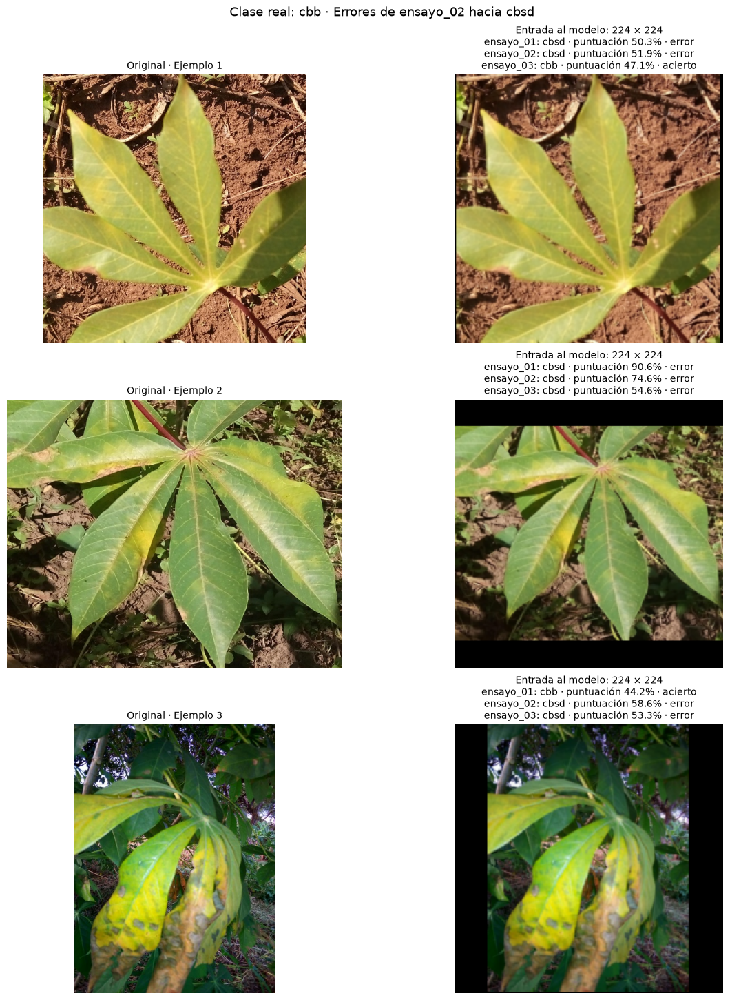

Errores encontrados con ese filtro: 31
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_02_cbb_a_cbsd.png
Ejemplo 1: validation-cmd-545.jpg
Ejemplo 2: validation-cmd-507.jpg
Ejemplo 3: validation-cmd-160.jpg


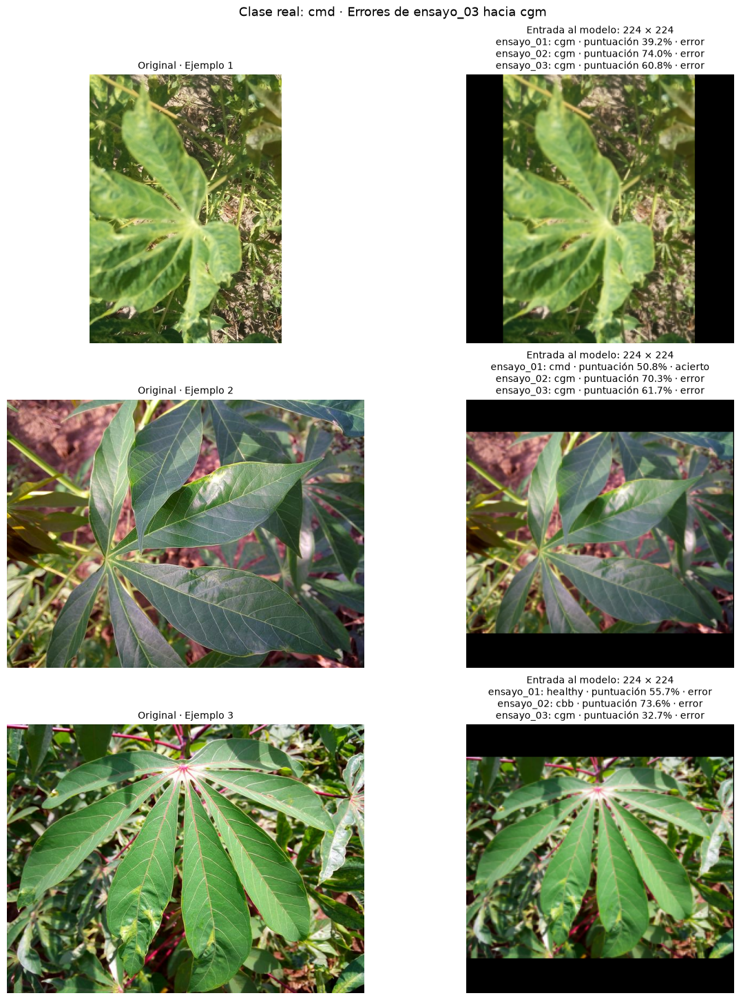

Errores encontrados con ese filtro: 88
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_03_cmd_a_cgm.png
Ejemplo 1: validation-cbsd-441.jpg
Ejemplo 2: validation-cbsd-436.jpg
Ejemplo 3: validation-cbsd-371.jpg


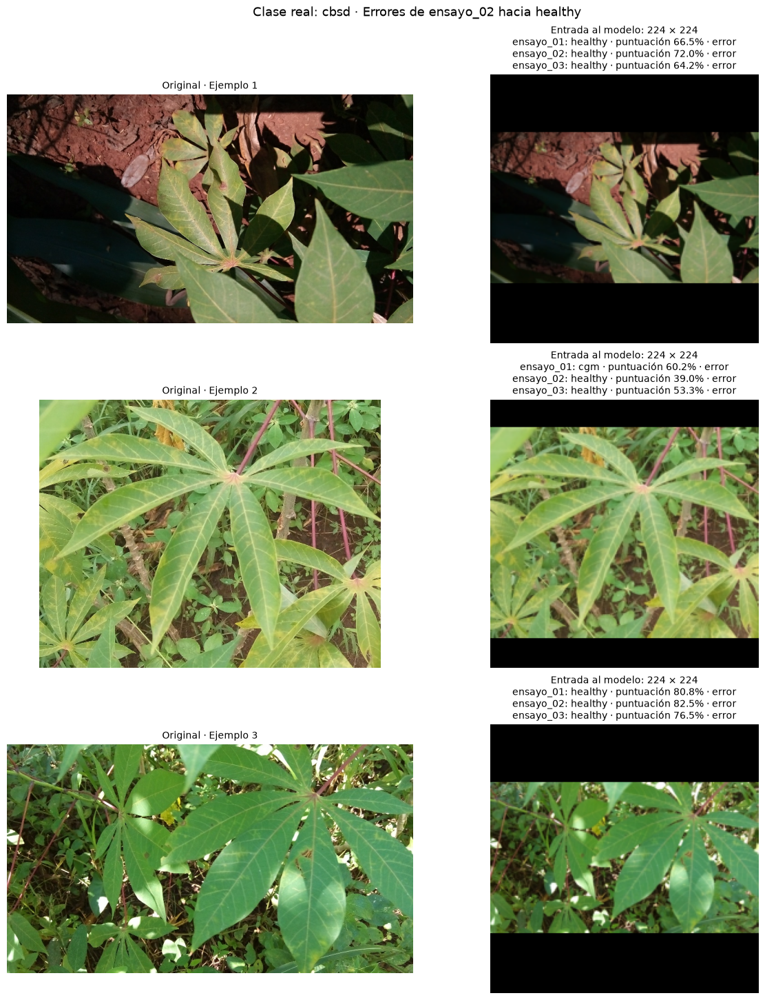

Errores encontrados con ese filtro: 20
Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\revision_imagenes_20261120_111346_114660\ensayo_02_cbsd_a_healthy.png


In [26]:
# Fotos realmente CBB que el segundo ensayo clasificó como CBSD.
mostrar_confusiones("ensayo_02", "cbb", "cbsd", cantidad=3)

# Fotos realmente CMD que el tercer ensayo clasificó como CGM.
mostrar_confusiones("ensayo_03", "cmd", "cgm", cantidad=3)

# Hojas con CBSD que el segundo ensayo clasificó como sanas.
mostrar_confusiones("ensayo_02", "cbsd", "healthy", cantidad=3)

In [27]:
# PASO 26: Construir la CNN del cuarto ensayo con pesos nuevos.
# Reutiliza las funciones definidas en el Paso 9.

def construir_cnn_04(tamano_imagen, numero_clases):
    entrada = keras.Input(
        shape=(*tamano_imagen, 3),
        name="imagen_rgb",
    )
    x = layers.Rescaling(
        1.0 / 255,
        name="normalizacion",
    )(entrada)

    # Primera reducción: 224 x 224 -> 112 x 112.
    x = convolucion_inicial(x, 32, 3, paso=2)

    # Cambio del cuarto ensayo:
    # procesar características conservando 112 x 112.
    x = convolucion_inicial(x, 32, 3, paso=1)

    # Segunda reducción: 112 x 112 -> 56 x 56.
    x = convolucion_inicial(x, 32, 3, paso=2)

    # Mantener los grupos ligeros, la atención y las conexiones densas.
    configuracion_grupos = [
        (16, 48),
        (24, 80),
        (32, 128),
    ]

    for indice, (crecimiento, canales_salida) in enumerate(
        configuracion_grupos
    ):
        for _ in range(3):
            x = bloque_ligero_denso(x, crecimiento)

        x = convolucion_inicial(x, canales_salida, 1)

        if indice < len(configuracion_grupos) - 1:
            x = layers.AveragePooling2D(2)(x)

    x = layers.GlobalAveragePooling2D(
        name="resumen_global",
    )(x)

    # Recuperar el dropout del segundo ensayo.
    x = layers.Dropout(
        0.30,
        name="regularizacion",
    )(x)

    salida = layers.Dense(
        numero_clases,
        activation="softmax",
        name="clasificacion",
    )(x)

    return keras.Model(
        entrada,
        salida,
        name="cnn_propia_ajustada_04",
    )


if tuple(IMG_SIZE) != (224, 224) or len(clases) != 5:
    raise ValueError(
        "Este ensayo espera imágenes de 224 x 224 y las cinco clases."
    )

keras.backend.clear_session()
keras.utils.set_random_seed(42)

nucleo_04 = construir_cnn_04(IMG_SIZE, len(clases))

entrada_04 = keras.Input(
    shape=(*IMG_SIZE, 3),
    name="imagen_rgb_ensayo_04",
)

imagen_aumentada_04 = layers.RandomFlip(
    mode="horizontal",
    seed=43,
    name="volteo_solo_train",
)(entrada_04)

salida_04 = nucleo_04(imagen_aumentada_04)

modelo_04 = keras.Model(
    entrada_04,
    salida_04,
    name="cnn_ajustada_extraccion_intermedia",
)

# Mostrar una tabla compacta de la arquitectura.
modelo_04.summary(expand_nested=False)

print("\nCuarto ensayo: extracción antes de la segunda reducción")
print("Recorrido inicial: 224 -> 112 -> 112 -> 56")
print(f"Parámetros totales: {modelo_04.count_params():,}")
print("Dropout: 0.30")
print("Modelo construido con pesos nuevos. Todavía no se entrenó.")

Model: "cnn_ajustada_extraccion_intermedia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb_ensayo_04            │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ volteo_solo_train (RandomFlip)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_propia_ajustada_04          │ (None, 5)              │       375,297 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 375,297 (1.43 MB)

 Trainable params: 368,593 (1.41 MB)

 Non-trainable params: 6,704 (26.19 KB)


Cuarto ensayo: extracción antes de la segunda reducción
Recorrido inicial: 224 -> 112 -> 112 -> 56
Parámetros totales: 375,297
Dropout: 0.30
Modelo construido con pesos nuevos. Todavía no se entrenó.


In [28]:
# PASO 27: Configuración del cuarto ensayo.

EPOCAS_MAXIMAS_04 = 20
TASA_INICIAL_04 = 0.0003
PACIENCIA_04 = 6

# Mantener la misma compensación de las cinco clases.
# Los pesos se calculan únicamente con los conteos de Train.
conteos_train_04 = np.asarray(
    conteos["Train"],
    dtype=np.float64,
)

if (
    len(conteos_train_04) != len(clases)
    or np.any(conteos_train_04 <= 0)
):
    raise ValueError(
        "Revisa los conteos de Train y el orden de las clases."
    )

pesos_04 = 1.0 / np.sqrt(conteos_train_04)
pesos_04 /= np.average(
    pesos_04,
    weights=conteos_train_04,
)

pesos_clase_04 = {
    indice: float(peso)
    for indice, peso in enumerate(pesos_04)
}

modelo_04.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=TASA_INICIAL_04,
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Reutilizar la preparación actual.
train_04 = preparar_dataset(
    ds_train,
    entrenamiento=True,
)

print("Cuarto ensayo: CNN con extracción intermedia")
print(f"Máximo de épocas: {EPOCAS_MAXIMAS_04}")
print(f"Tasa de aprendizaje inicial: {TASA_INICIAL_04}")
print(f"Paciencia de parada temprana: {PACIENCIA_04}")
print(f"Tamaño de imagen: {IMG_SIZE}")
print(f"Tamaño de lote: {BATCH_SIZE}")
print("Optimizador: Adam")
print("Pérdida: SparseCategoricalCrossentropy")
print("Modelo guardado según: menor val_loss")
print("Aumento durante entrenamiento: volteo horizontal aleatorio")
print("Dropout: 0.30")
print("Cambio: convolución adicional antes de la segunda reducción")
print("Evaluación durante entrenamiento: Validation")

print("\nClase       Fotos     Peso")
for i, nombre in enumerate(clases):
    print(
        f"{nombre:<10} {int(conteos_train_04[i]):>5}"
        f" {pesos_clase_04[i]:>8.2f}"
    )

Cuarto ensayo: CNN con extracción intermedia
Máximo de épocas: 20
Tasa de aprendizaje inicial: 0.0003
Paciencia de parada temprana: 6
Tamaño de imagen: (224, 224)
Tamaño de lote: 32
Optimizador: Adam
Pérdida: SparseCategoricalCrossentropy
Modelo guardado según: menor val_loss
Aumento durante entrenamiento: volteo horizontal aleatorio
Dropout: 0.30
Cambio: convolución adicional antes de la segunda reducción
Evaluación durante entrenamiento: Validation

Clase       Fotos     Peso
cbb          466     1.67
cbsd        1443     0.95
cgm          773     1.30
cmd         2658     0.70
healthy      316     2.03


In [29]:
# PASO 28: Entrenar el cuarto ensayo y guardar el mejor modelo.

actual_04 = Path.cwd()
cassava_04 = (
    actual_04
    if actual_04.name.lower() == "cassava"
    else actual_04 / "cassava"
)

if not (cassava_04 / "CNN_Propia_ajustada.ipynb").is_file():
    raise FileNotFoundError(
        "Ejecuta desde la carpeta BeanCass AI "
        "o desde su carpeta cassava."
    )

nombre_04 = datetime.now().strftime(
    "ensayo_04_extraccion_intermedia_%Y%m%d_%H%M%S_%f"
)

carpeta_corrida_04 = (
    cassava_04
    / "resultados"
    / "cnn_propia_ajustada"
    / nombre_04
)
carpeta_corrida_04.mkdir(
    parents=True,
    exist_ok=False,
)

ruta_modelo_04 = carpeta_corrida_04 / "mejor_modelo.keras"

callbacks_04 = [
    keras.callbacks.CSVLogger(
        str(carpeta_corrida_04 / "historial.csv"),
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_modelo_04),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PACIENCIA_04,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.TerminateOnNaN(),
]

print("Resultados de esta corrida:", carpeta_corrida_04.resolve())

inicio_04 = perf_counter()

historial_04 = modelo_04.fit(
    train_04,
    validation_data=val_preparado,
    class_weight=pesos_clase_04,
    epochs=EPOCAS_MAXIMAS_04,
    shuffle=False,
    callbacks=callbacks_04,
    verbose=1,
)

duracion_04 = perf_counter() - inicio_04
mejor_indice_04 = int(
    np.argmin(historial_04.history["val_loss"])
)

print(
    f"\nÉpocas ejecutadas: "
    f"{len(historial_04.history['loss'])}"
)
print(f"Época guardada: {mejor_indice_04 + 1}")
print(
    "Exactitud en validación: "
    f"{historial_04.history['val_accuracy'][mejor_indice_04]:.2%}"
)
print(
    "Pérdida en validación: "
    f"{historial_04.history['val_loss'][mejor_indice_04]:.4f}"
)
print(
    f"Tiempo de entrenamiento: "
    f"{duracion_04 / 60:.2f} minutos"
)
print(
    "Archivos guardados en:",
    carpeta_corrida_04.resolve(),
)

Resultados de esta corrida: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_04_extraccion_intermedia_20261120_114132_552714
Epoch 1/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 196s 946ms/step - accuracy: 0.5217 - loss: 1.3530 - val_accuracy: 0.5638 - val_loss: 1.1469 - learning_rate: 3.0000e-04
Epoch 2/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 168s 944ms/step - accuracy: 0.5896 - loss: 1.2159 - val_accuracy: 0.6098 - val_loss: 1.0629 - learning_rate: 3.0000e-04
Epoch 3/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 154s 869ms/step - accuracy: 0.6245 - loss: 1.1424 - val_accuracy: 0.6363 - val_loss: 1.0183 - learning_rate: 3.0000e-04
Epoch 4/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 150s 844ms/step - accuracy: 0.6407 - loss: 1.0940 - val_accuracy: 0.6570 - val_loss: 0.9431 - learning_rate: 3.0000e-04
Epoch 5/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 151s 847ms/step - accuracy: 0.6549 - loss: 1.0403 - val_accuracy: 0.5945 - val_loss: 1.0832 - learning_ra

In [30]:
# PASO 29: Evaluar el mejor modelo guardado del cuarto ensayo.

# Leer el historial para identificar la época guardada.
with (carpeta_corrida_04 / "historial.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    filas_historial_04 = list(csv.DictReader(archivo))

mejor_fila_04 = min(
    filas_historial_04,
    key=lambda fila: float(fila["val_loss"]),
)
epoca_guardada_04 = int(mejor_fila_04["epoch"]) + 1

# Cargar el modelo guardado, no el de la última época.
modelo_evaluado_04 = keras.models.load_model(
    carpeta_corrida_04 / "mejor_modelo.keras",
    compile=False,
)

# Filas: clase real. Columnas: clase predicha.
matriz_04 = np.zeros(
    (len(clases), len(clases)),
    dtype=np.int64,
)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_evaluado_04(
        imagenes, training=False
    ).numpy()

    predicciones = np.argmax(probabilidades, axis=1)
    etiquetas_reales = etiquetas.numpy().astype(int).reshape(-1)

    np.add.at(
        matriz_04,
        (etiquetas_reales, predicciones),
        1,
    )

# Comprobar que se evaluó toda la partición de validación.
total_evaluadas_04 = int(matriz_04.sum())
total_esperadas_04 = int(info.splits["validation"].num_examples)

if total_evaluadas_04 != total_esperadas_04:
    raise ValueError(
        f"Se evaluaron {total_evaluadas_04} imágenes; "
        f"se esperaban {total_esperadas_04}."
    )

# Calcular las métricas por clase.
aciertos_04 = matriz_04.diagonal()
reales_04 = matriz_04.sum(axis=1)
predichas_04 = matriz_04.sum(axis=0)

precision_04 = np.divide(
    aciertos_04,
    predichas_04,
    out=np.zeros(len(clases), dtype=float),
    where=predichas_04 > 0,
)

recall_04 = np.divide(
    aciertos_04,
    reales_04,
    out=np.zeros(len(clases), dtype=float),
    where=reales_04 > 0,
)

f1_clases_04 = np.divide(
    2 * aciertos_04,
    reales_04 + predichas_04,
    out=np.zeros(len(clases), dtype=float),
    where=(reales_04 + predichas_04) > 0,
)

exactitud_04 = aciertos_04.sum() / total_evaluadas_04
f1_macro_04 = f1_clases_04.mean()

print(f"Épocas ejecutadas: {len(filas_historial_04)}")
print(f"Época guardada y evaluada: {epoca_guardada_04}")
print(f"Imágenes de validación: {total_evaluadas_04}")
print(f"Exactitud en validación: {exactitud_04:.2%}")
print(f"F1 macro: {f1_macro_04:.4f}")

print(
    f"\n{'Clase':<10} {'Aciertos':>10} "
    f"{'Precisión':>12} {'Recall':>10} {'F1':>10}"
)

for i, nombre in enumerate(clases):
    cantidad = f"{aciertos_04[i]}/{reales_04[i]}"
    print(
        f"{nombre:<10} {cantidad:>10} "
        f"{precision_04[i]:>12.2%} "
        f"{recall_04[i]:>10.2%} "
        f"{f1_clases_04[i]:>10.4f}"
    )

# Mostrar confusiones relevantes de las cinco clases.
indices_clases_04 = {
    nombre: i for i, nombre in enumerate(clases)
}

print()
for real, predicha in [
    ("cbb", "cbsd"),
    ("cbsd", "cmd"),
    ("cgm", "cmd"),
    ("cmd", "cgm"),
    ("healthy", "cmd"),
]:
    cantidad = matriz_04[
        indices_clases_04[real],
        indices_clases_04[predicha],
    ]
    print(f"{real} → {predicha}: {cantidad}")

indice_sana_04 = indices_clases_04["healthy"]
enfermas_como_sanas_04 = int(
    matriz_04[:, indice_sana_04].sum()
    - matriz_04[indice_sana_04, indice_sana_04]
)

print(
    "Hojas enfermas predichas como sanas:",
    enfermas_como_sanas_04,
)

Épocas ejecutadas: 20
Época guardada y evaluada: 18
Imágenes de validación: 1889
Exactitud en validación: 73.74%
F1 macro: 0.6518

Clase        Aciertos    Precisión     Recall         F1
cbb            88/156       57.14%     56.41%     0.5677
cbsd          345/482       77.35%     71.58%     0.7435
cgm           156/258       51.49%     60.47%     0.5561
cmd           744/887       85.32%     83.88%     0.8459
healthy        60/106       52.63%     56.60%     0.5455

cbb → cbsd: 29
cbsd → cmd: 49
cgm → cmd: 53
cmd → cgm: 86
healthy → cmd: 9
Hojas enfermas predichas como sanas: 54


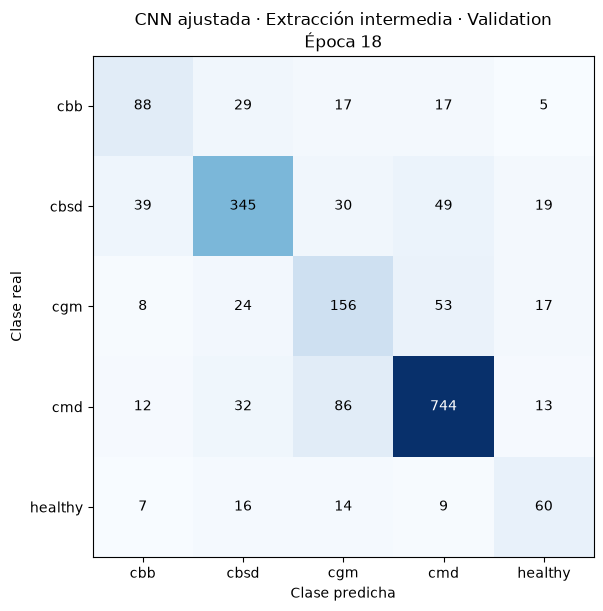

Matriz guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_04_extraccion_intermedia_20261120_114132_552714\matriz_confusion_validacion.png


In [31]:
# PASO 30: Matriz de confusión del cuarto ensayo en Validation.
# Requiere haber ejecutado el Paso 29.

fig, eje = plt.subplots(
    figsize=(7, 6),
    layout="constrained",
)

eje.imshow(matriz_04, cmap="Blues")

eje.set_xticks(range(len(clases)), labels=clases)
eje.set_yticks(range(len(clases)), labels=clases)

eje.set(
    title=(
        "CNN ajustada · Extracción intermedia · Validation"
        f"\nÉpoca {epoca_guardada_04}"
    ),
    xlabel="Clase predicha",
    ylabel="Clase real",
)

for fila, columna in np.ndindex(matriz_04.shape):
    valor = matriz_04[fila, columna]
    color = (
        "white"
        if valor > matriz_04.max() / 2
        else "black"
    )

    eje.text(
        columna,
        fila,
        str(valor),
        ha="center",
        va="center",
        color=color,
    )

ruta_matriz_04 = (
    carpeta_corrida_04 / "matriz_confusion_validacion.png"
)

fig.savefig(ruta_matriz_04, dpi=200)
plt.show()
plt.close(fig)

print("Matriz guardada en:", ruta_matriz_04.resolve())

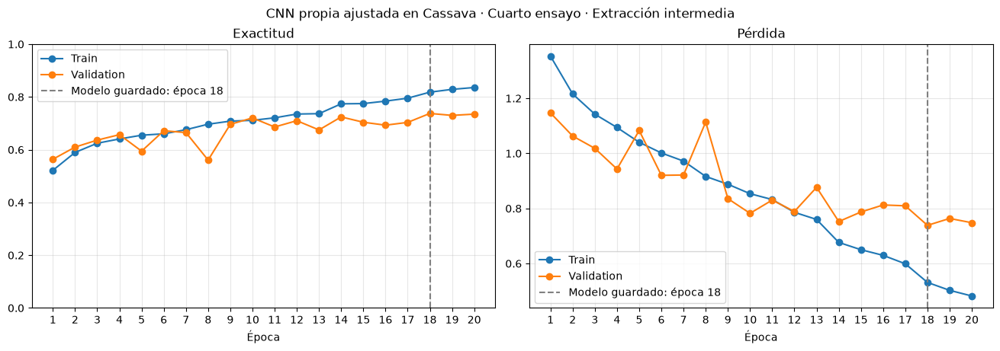

Máximo configurado: 20 épocas
Épocas ejecutadas: 20
Época seleccionada por menor val_loss: 18
Curvas guardadas en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia_ajustada\ensayo_04_extraccion_intermedia_20261120_114132_552714\curvas_entrenamiento.png


In [32]:
# PASO 31: Curvas de entrenamiento del cuarto ensayo.
# Utiliza el historial leído en el Paso 29.

epocas_grafica_04 = [
    int(fila["epoch"]) + 1
    for fila in filas_historial_04
]

fig, ejes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    layout="constrained",
)

fig.suptitle(
    "CNN propia ajustada en Cassava · Cuarto ensayo"
    " · Extracción intermedia"
)

for eje, metrica, titulo in zip(
    ejes,
    ("accuracy", "loss"),
    ("Exactitud", "Pérdida"),
):
    valores_train = [
        float(fila[metrica])
        for fila in filas_historial_04
    ]
    valores_val = [
        float(fila[f"val_{metrica}"])
        for fila in filas_historial_04
    ]

    eje.plot(
        epocas_grafica_04,
        valores_train,
        marker="o",
        label="Train",
    )
    eje.plot(
        epocas_grafica_04,
        valores_val,
        marker="o",
        label="Validation",
    )

    eje.axvline(
        epoca_guardada_04,
        color="gray",
        linestyle="--",
        label=f"Modelo guardado: época {epoca_guardada_04}",
    )

    eje.set(
        title=titulo,
        xlabel="Época",
        xticks=epocas_grafica_04,
    )
    eje.grid(alpha=0.3)
    eje.legend()

# La exactitud se expresa entre 0 y 1.
ejes[0].set_ylim(0, 1)

ruta_curvas_04 = (
    carpeta_corrida_04 / "curvas_entrenamiento.png"
)

fig.savefig(ruta_curvas_04, dpi=200)
plt.show()
plt.close(fig)

print(f"Máximo configurado: {EPOCAS_MAXIMAS_04} épocas")
print(f"Épocas ejecutadas: {len(filas_historial_04)}")
print(
    "Época seleccionada por menor val_loss:",
    epoca_guardada_04,
)
print("Curvas guardadas en:", ruta_curvas_04.resolve())